
# Predictive Modelling: Supply Chain Demand Prediction

## 1. Project Overview

This notebook develops and evaluates machine-learning models for predicting daily units sold within a supply chain and inventory management environment.

The analysis builds on the data understanding, exploratory data analysis, and statistical investigation completed in the preceding notebooks.

The primary objective is to investigate whether historical sales patterns and available operational variables can be used to predict daily product demand.

## 2. Business Problem

Accurate demand prediction can support supply chain activities such as:

- Inventory planning.
- Replenishment decisions.
- Warehouse operations.
- Demand forecasting.
- Stock management.

Inaccurate demand predictions may contribute to inefficient inventory allocation, excess inventory, or insufficient stock availability.

## 3. Prediction Objective

**Target variable:** `Units_Sold`

The target represents the number of units sold for a particular SKU and warehouse on a given date.

The modelling task will be formulated as a supervised regression problem.

## 4. Analytical Approach

The notebook will investigate the following stages:

1. Load and inspect the original dataset.
2. Prepare modelling variables.
3. Engineer appropriate historical features.
4. Create time-aware training, validation, and testing datasets.
5. Establish baseline forecasting models.
6. Train and evaluate machine-learning regression models.
7. Compare model performance.
8. Interpret model results and document limitations.

## 5. Model Evaluation

The models will be evaluated using appropriate regression metrics, including:

- Mean Absolute Error (MAE).
- Root Mean Squared Error (RMSE).
- Mean Absolute Percentage Error (MAPE), only where appropriate.
- Coefficient of Determination (R²).

Model evaluation will prioritise performance on observations occurring after the training period.

## 6. Important Methodological Considerations

- The original dataset will be preserved.
- Historical features will be constructed without using future information.
- Random train-test splitting will be avoided because the data are time-ordered.
- The constant `Stockout_Flag` variable will not be used as a predictive feature.
- The supplied `Demand_Forecast` will not automatically be treated as a valid input feature because its forecasting methodology and information availability are unknown.
- Model performance will be compared against simple baselines.
- Predictive relationships will not be interpreted as causal relationships.

## 7. Tools and Libraries

Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

## 8. Expected Outcome

A reproducible predictive modelling workflow that demonstrates data preparation, feature engineering, time-aware model validation, model evaluation, and interpretation of demand predictions.


In [5]:
# STEP 2: IMPORT THE REQUIRED PYTHON LIBRARIES

# Data manipulation and numerical operations.
import pandas as pd
import numpy as np

# Data visualisation.
import matplotlib.pyplot as plt
import seaborn as sns

# Machine-learning preprocessing and evaluation.
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display settings for clearer tables.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

# Apply a consistent visual style to charts.
sns.set_theme(style="whitegrid")

# Set a random seed for reproducibility.
RANDOM_STATE = 42

# Confirm that the libraries have loaded successfully.
print("Required libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Required libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.4.6


In [6]:
# STEP 3: UPLOAD AND LOAD THE ORIGINAL DATASET

# Import the Google Colab file-upload utility.
from google.colab import files

# Upload the original CSV dataset from your computer.
uploaded = files.upload()

# Identify the uploaded CSV filename.
file_name = "supply_chain_dataset1.csv"

# Load the original dataset into a Pandas DataFrame.
df = pd.read_csv(file_name)

# Preserve an unchanged copy of the original loaded data.
df_original = df.copy()

# Convert the Date column to datetime format.
df["Date"] = pd.to_datetime(df["Date"], errors="raise")

# Sort observations chronologically within each SKU-warehouse group.
df = df.sort_values(
    ["SKU_ID", "Warehouse_ID", "Date"]
).reset_index(drop=True)

# Display the dataset dimensions.
print("Dataset loaded successfully.")
print("Dataset dimensions:", df.shape)

# Display the first five observations.
display(df.head())

Saving supply_chain_dataset1.csv to supply_chain_dataset1 (1).csv
Dataset loaded successfully.
Dataset dimensions: (91250, 15)


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.9500,20.4800,0,0,8.5200
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.9500,20.4800,0,0,18.6300
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.9500,20.4800,1,0,39.6200
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.9500,20.4800,0,0,19.4300
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.9500,20.4800,0,0,18.7000


In [7]:
# STEP 4: INSPECT THE DATASET BEFORE FEATURE ENGINEERING

# Display the dataset dimensions.
print("DATASET DIMENSIONS")
print("=" * 60)
print(df.shape)

# Display all column names and data types.
print("\nCOLUMN INFORMATION")
print("=" * 60)
df.info()

# Count missing values in each column.
print("\nMISSING VALUES")
print("=" * 60)
display(df.isna().sum().to_frame("Missing_Values"))

# Check duplicate complete records.
print("\nDUPLICATE RECORDS")
print("=" * 60)
print(df.duplicated().sum())

# Check the date range.
print("\nDATE RANGE")
print("=" * 60)
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

# Count unique products, warehouses and operational groups.
print("\nUNIQUE CATEGORY COUNTS")
print("=" * 60)
print("SKUs:", df["SKU_ID"].nunique())
print("Warehouses:", df["Warehouse_ID"].nunique())
print("Suppliers:", df["Supplier_ID"].nunique())

# Display the target variable distribution.
print("\nTARGET VARIABLE: UNITS SOLD")
print("=" * 60)
display(df["Units_Sold"].describe().to_frame())

# Check the number of zero-sales observations.
print("\nZERO-SALES OBSERVATIONS")
print("=" * 60)
print((df["Units_Sold"] == 0).sum())

DATASET DIMENSIONS
(91250, 15)

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91250 entries, 0 to 91249
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     91250 non-null  datetime64[ns]
 1   SKU_ID                   91250 non-null  object        
 2   Warehouse_ID             91250 non-null  object        
 3   Supplier_ID              91250 non-null  object        
 4   Region                   91250 non-null  object        
 5   Units_Sold               91250 non-null  int64         
 6   Inventory_Level          91250 non-null  int64         
 7   Supplier_Lead_Time_Days  91250 non-null  int64         
 8   Reorder_Point            91250 non-null  int64         
 9   Order_Quantity           91250 non-null  int64         
 10  Unit_Cost                91250 non-null  float64       
 11  Unit_Price               91250 non-null  f

,Missing_Values
Date,0
SKU_ID,0
Warehouse_ID,0
Supplier_ID,0
Region,0
Units_Sold,0
Inventory_Level,0
Supplier_Lead_Time_Days,0
Reorder_Point,0
Order_Quantity,0



DUPLICATE RECORDS
0

DATE RANGE
First date: 2024-01-01 00:00:00
Last date: 2024-12-30 00:00:00

UNIQUE CATEGORY COUNTS
SKUs: 50
Warehouses: 5
Suppliers: 10

TARGET VARIABLE: UNITS SOLD


,Units_Sold
count,"91,250.0000"
mean,20.0546
std,9.0686
min,0.0000
25%,13.0000
50%,20.0000
75%,27.0000
max,59.0000



ZERO-SALES OBSERVATIONS
620


In [8]:
# STEP 5: VALIDATE TIME-SERIES STRUCTURE AND VARIABLE BEHAVIOUR

# Create a unique identifier for each SKU-warehouse combination.
df["SKU_Warehouse_Group"] = (
    df["SKU_ID"].astype(str)
    + "_"
    + df["Warehouse_ID"].astype(str)
)

# Calculate the number of unique operational groups.
number_of_groups = df["SKU_Warehouse_Group"].nunique()

# Count daily observations within each operational group.
group_observation_counts = (
    df.groupby("SKU_Warehouse_Group")
    .size()
)

# Calculate the time difference between consecutive observations
# within each SKU-warehouse group.
df["Date_Gap"] = (
    df.groupby("SKU_Warehouse_Group")["Date"]
    .diff()
)

# Count date gaps that are not exactly one day.
irregular_date_gaps = (
    df["Date_Gap"].notna()
    & (df["Date_Gap"] != pd.Timedelta(days=1))
).sum()

# Display the time-series structure.
print("TIME-SERIES STRUCTURE")
print("=" * 70)
print("Unique SKU-Warehouse groups:", number_of_groups)
print("Total observations:", len(df))
print("Minimum observations per group:", group_observation_counts.min())
print("Maximum observations per group:", group_observation_counts.max())
print("Irregular consecutive date gaps:", irregular_date_gaps)

# Identify variables that are constant within every SKU-warehouse group.
# This helps distinguish potentially stable characteristics from
# variables that change over time.
variables_to_inspect = [
    "Supplier_ID",
    "Region",
    "Supplier_Lead_Time_Days",
    "Reorder_Point",
    "Unit_Cost",
    "Unit_Price",
    "Promotion_Flag",
    "Stockout_Flag"
]

# Count the number of groups in which each variable changes.
variation_results = []

for column in variables_to_inspect:

    # Calculate the number of unique values in each group.
    unique_values_per_group = (
        df.groupby("SKU_Warehouse_Group")[column]
        .nunique()
    )

    # Count groups with more than one unique value.
    varying_groups = (
        unique_values_per_group > 1
    ).sum()

    # Count groups with exactly one unique value.
    constant_groups = (
        unique_values_per_group == 1
    ).sum()

    # Store the results.
    variation_results.append({
        "Variable": column,
        "Groups_With_Variation": varying_groups,
        "Groups_Constant": constant_groups
    })

# Convert the results into a DataFrame.
variable_variation_summary = pd.DataFrame(
    variation_results
)

# Display the variable variation summary.
print("\nVARIABLE VARIATION WITHIN SKU-WAREHOUSE GROUPS")
print("=" * 70)
display(variable_variation_summary)

# Remove the temporary date-gap column.
# The original Date column and observation order remain unchanged.
df.drop(columns=["Date_Gap"], inplace=True)

TIME-SERIES STRUCTURE
Unique SKU-Warehouse groups: 250
Total observations: 91250
Minimum observations per group: 365
Maximum observations per group: 365
Irregular consecutive date gaps: 0

VARIABLE VARIATION WITHIN SKU-WAREHOUSE GROUPS


,Variable,Groups_With_Variation,Groups_Constant
0,Supplier_ID,0,250
1,Region,250,0
2,Supplier_Lead_Time_Days,0,250
3,Reorder_Point,0,250
4,Unit_Cost,0,250
5,Unit_Price,0,250
6,Promotion_Flag,250,0
7,Stockout_Flag,0,250



# Step 6: Prediction Timing and Feature Engineering

## Prediction Definition

This project formulates demand prediction as a one-day-ahead supervised regression problem.

For each SKU-warehouse combination, information available up to the end of day *t* will be used to predict `Units_Sold` on day *t+1*.

## Target Variable

`Target_Next_Day_Units_Sold`

This represents the following day's observed sales for the same SKU-warehouse combination.

## Historical Sales Features

The initial feature set will include:

- `Sales_Lag_1`: sales observed on the forecast-origin day.
- `Sales_Lag_7`: sales observed six days before the forecast-origin day.
- `Sales_Lag_14`: sales observed thirteen days before the forecast-origin day.
- `Sales_Lag_28`: sales observed twenty-seven days before the forecast-origin day.
- `Rolling_Mean_7`: average sales over the seven observations ending on the forecast-origin day.
- `Rolling_Mean_14`: average sales over the fourteen observations ending on the forecast-origin day.
- `Rolling_Mean_28`: average sales over the twenty-eight observations ending on the forecast-origin day.

These features use only sales observations available at the forecast origin.

## Calendar Features

The target date will be used to derive:

- Day of the week.
- Month.
- Weekend indicator.

These calendar characteristics are known in advance.

## Categorical Features

The initial modelling process may include SKU, warehouse and supplier identifiers as categorical variables.

Supplier assignment is constant within each SKU-warehouse combination in this dataset.

## Excluded Variables

The initial model will exclude:

- `Inventory_Level`: recorded inventory is affected by same-day operational activity.
- `Order_Quantity`: its exact availability at the forecast origin is not established.
- `Promotion_Flag`: advance availability of promotion information is not established.
- `Stockout_Flag`: constant at zero.
- `Demand_Forecast`: original forecasting methodology and information availability are unknown.
- `Region`: changes within SKU-warehouse groups and its meaning requires further clarification.

## Data Leakage Prevention

The target is shifted forward by one observation within each SKU-warehouse group.

Historical sales features are constructed using only observations available at the forecast origin. The final observation in each group has no next-day target and will be excluded.

Rolling averages include the forecast-origin day's observed sales, which are assumed to be available before the next-day prediction is made.


In [9]:
# STEP 6B: CREATE THE NEXT-DAY TARGET AND HISTORICAL FEATURES

# Create a separate modelling DataFrame.
# This preserves the original dataset in df.
df_model = df.copy()

# Sort observations within each SKU-warehouse group by date.
df_model = df_model.sort_values(
    ["SKU_Warehouse_Group", "Date"]
).reset_index(drop=True)

# Create a grouped object for time-series calculations.
grouped_sales = df_model.groupby("SKU_Warehouse_Group")["Units_Sold"]

# ------------------------------------------------------------
# 1. CREATE THE NEXT-DAY TARGET
# ------------------------------------------------------------

# Shift sales backwards by one row within each group.
# This assigns the following day's sales to the current row.
df_model["Target_Next_Day_Units_Sold"] = (
    grouped_sales.shift(-1)
)

# Record the actual date associated with the target observation.
df_model["Target_Date"] = (
    df_model.groupby("SKU_Warehouse_Group")["Date"].shift(-1)
)

# ------------------------------------------------------------
# 2. CREATE HISTORICAL SALES FEATURES
# ------------------------------------------------------------

# Sales observed on the forecast-origin date.
df_model["Sales_Lag_1"] = grouped_sales.shift(0)

# Sales observed six days before the forecast origin.
# This is seven days before the next-day target.
df_model["Sales_Lag_7"] = grouped_sales.shift(6)

# Sales observed thirteen days before the forecast origin.
df_model["Sales_Lag_14"] = grouped_sales.shift(13)

# Sales observed twenty-seven days before the forecast origin.
df_model["Sales_Lag_28"] = grouped_sales.shift(27)

# ------------------------------------------------------------
# 3. CREATE ROLLING SALES AVERAGES
# ------------------------------------------------------------

# Calculate the seven-observation rolling average.
# The current forecast-origin day's sales are included.
df_model["Rolling_Mean_7"] = (
    df_model.groupby("SKU_Warehouse_Group")["Units_Sold"]
    .transform(lambda series: series.rolling(7).mean())
)

# Calculate the fourteen-observation rolling average.
df_model["Rolling_Mean_14"] = (
    df_model.groupby("SKU_Warehouse_Group")["Units_Sold"]
    .transform(lambda series: series.rolling(14).mean())
)

# Calculate the twenty-eight-observation rolling average.
df_model["Rolling_Mean_28"] = (
    df_model.groupby("SKU_Warehouse_Group")["Units_Sold"]
    .transform(lambda series: series.rolling(28).mean())
)

# ------------------------------------------------------------
# 4. CREATE CALENDAR FEATURES FOR THE TARGET DATE
# ------------------------------------------------------------

# Extract the target date's day of the week.
# Monday = 0 and Sunday = 6.
df_model["Target_Day_of_Week"] = (
    df_model["Target_Date"].dt.dayofweek
)

# Extract the target date's month.
df_model["Target_Month"] = (
    df_model["Target_Date"].dt.month
)

# Identify whether the target date falls on a weekend.
df_model["Target_Is_Weekend"] = (
    df_model["Target_Day_of_Week"].isin([5, 6]).astype(int)
)

# ------------------------------------------------------------
# 5. REMOVE OBSERVATIONS WITH INCOMPLETE FEATURES OR TARGETS
# ------------------------------------------------------------

# List all variables required for the initial modelling dataset.
required_model_columns = [
    "Target_Next_Day_Units_Sold",
    "Target_Date",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_28",
    "Target_Day_of_Week",
    "Target_Month",
    "Target_Is_Weekend"
]

# Count observations before removing incomplete rows.
observations_before_filtering = len(df_model)

# Remove rows that have missing target or engineered features.
df_model = df_model.dropna(
    subset=required_model_columns
).copy()

# Reset the DataFrame index.
df_model = df_model.reset_index(drop=True)

# ------------------------------------------------------------
# 6. DISPLAY FEATURE-ENGINEERING RESULTS
# ------------------------------------------------------------

print("FEATURE ENGINEERING SUMMARY")
print("=" * 70)

print("Original observations:", observations_before_filtering)
print("Observations after feature engineering:", len(df_model))
print("Observations removed:", observations_before_filtering - len(df_model))

print("\nMODELLING DATASET DIMENSIONS")
print("=" * 70)
print(df_model.shape)

print("\nMISSING VALUES IN REQUIRED FEATURES")
print("=" * 70)
display(
    df_model[required_model_columns]
    .isna()
    .sum()
    .to_frame("Missing_Values")
)

print("\nTARGET DATE RANGE")
print("=" * 70)
print("First target date:", df_model["Target_Date"].min())
print("Last target date:", df_model["Target_Date"].max())

print("\nFEATURE AND TARGET PREVIEW")
print("=" * 70)

display(
    df_model[
        [
            "SKU_ID",
            "Warehouse_ID",
            "Date",
            "Target_Date",
            "Units_Sold",
            "Sales_Lag_7",
            "Rolling_Mean_7",
            "Rolling_Mean_28",
            "Target_Next_Day_Units_Sold"
        ]
    ].head(10)
)

FEATURE ENGINEERING SUMMARY
Original observations: 91250
Observations after feature engineering: 84250
Observations removed: 7000

MODELLING DATASET DIMENSIONS
(84250, 28)

MISSING VALUES IN REQUIRED FEATURES


,Missing_Values
Target_Next_Day_Units_Sold,0
Target_Date,0
Sales_Lag_1,0
Sales_Lag_7,0
Sales_Lag_14,0
Sales_Lag_28,0
Rolling_Mean_7,0
Rolling_Mean_14,0
Rolling_Mean_28,0
Target_Day_of_Week,0



TARGET DATE RANGE
First target date: 2024-01-29 00:00:00
Last target date: 2024-12-30 00:00:00

FEATURE AND TARGET PREVIEW


,SKU_ID,Warehouse_ID,Date,Target_Date,Units_Sold,Sales_Lag_7,Rolling_Mean_7,Rolling_Mean_28,Target_Next_Day_Units_Sold
0,SKU_10,WH_1,2024-01-28,2024-01-29,28,26.0000,23.8571,22.5357,24.0000
1,SKU_10,WH_1,2024-01-29,2024-01-30,24,24.0000,23.5714,22.5357,26.0000
2,SKU_10,WH_1,2024-01-30,2024-01-31,26,22.0000,23.8571,22.6429,27.0000
3,SKU_10,WH_1,2024-01-31,2024-02-01,27,25.0000,24.5714,22.7143,27.0000
4,SKU_10,WH_1,2024-02-01,2024-02-02,27,20.0000,24.8571,22.9643,9.0000
5,SKU_10,WH_1,2024-02-02,2024-02-03,9,22.0000,23.2857,22.5000,32.0000
6,SKU_10,WH_1,2024-02-03,2024-02-04,32,28.0000,24.7143,22.9286,23.0000
7,SKU_10,WH_1,2024-02-04,2024-02-05,23,24.0000,24.0000,22.8929,44.0000
8,SKU_10,WH_1,2024-02-05,2024-02-06,44,26.0000,26.8571,23.6429,20.0000
9,SKU_10,WH_1,2024-02-06,2024-02-07,20,27.0000,26.0000,23.6786,30.0000



# Step 7: Time-Aware Training, Validation and Testing

## Objective

Separate the modelling observations into chronological training, validation and testing datasets.

## Splitting Strategy

The observations will be divided according to their target dates:

- Training dataset: earliest 70% of unique target dates.
- Validation dataset: following 15% of unique target dates.
- Testing dataset: final 15% of unique target dates.

All SKU-warehouse observations belonging to the same target date will be assigned to the same partition.

## Purpose of Each Dataset

**Training dataset**

Used to fit machine-learning models and learn relationships between historical features and next-day sales.

**Validation dataset**

Used to compare candidate models and make modelling decisions without using the final test observations.

**Testing dataset**

Reserved for the final evaluation of the selected model on later, unseen dates.

## Leakage Prevention

A random train-test split is not appropriate for this forecasting task because it can mix earlier and later observations.

Chronological splitting preserves the order of time. Historical features for validation and testing observations may use earlier observed sales, because these would be available at the corresponding forecast origins.

The final test dataset will not be used for model selection or hyperparameter tuning.


In [10]:
# STEP 7B: CREATE CHRONOLOGICAL TRAINING, VALIDATION AND TEST SETS

# Extract all unique target dates and sort them chronologically.
unique_target_dates = np.sort(
    df_model["Target_Date"].dropna().unique()
)

# Count the number of unique target dates.
number_of_target_dates = len(unique_target_dates)

# Calculate chronological split positions.
# The first 70% of dates will be used for training.
train_end_index = int(number_of_target_dates * 0.70)

# The next 15% of dates will be used for validation.
validation_end_index = int(number_of_target_dates * 0.85)

# Identify the date boundaries for each partition.
train_dates = unique_target_dates[:train_end_index]

validation_dates = unique_target_dates[
    train_end_index:validation_end_index
]

test_dates = unique_target_dates[
    validation_end_index:
]

# Create the three datasets using target-date membership.
# This ensures every SKU-warehouse observation for a given
# target date belongs to the same partition.
train_df = df_model[
    df_model["Target_Date"].isin(train_dates)
].copy()

validation_df = df_model[
    df_model["Target_Date"].isin(validation_dates)
].copy()

test_df = df_model[
    df_model["Target_Date"].isin(test_dates)
].copy()

# Reset the indices for each partition.
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# DISPLAY PARTITION SIZES AND DATE RANGES
# ------------------------------------------------------------

print("CHRONOLOGICAL DATA SPLIT")
print("=" * 70)

print("Total unique target dates:", number_of_target_dates)

# Create a summary table for the three partitions.
split_summary = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],
    "Observations": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Unique_Target_Dates": [
        train_df["Target_Date"].nunique(),
        validation_df["Target_Date"].nunique(),
        test_df["Target_Date"].nunique()
    ],
    "First_Target_Date": [
        train_df["Target_Date"].min(),
        validation_df["Target_Date"].min(),
        test_df["Target_Date"].min()
    ],
    "Last_Target_Date": [
        train_df["Target_Date"].max(),
        validation_df["Target_Date"].max(),
        test_df["Target_Date"].max()
    ]
})

display(split_summary)

# ------------------------------------------------------------
# VALIDATE THE CHRONOLOGICAL SPLIT
# ------------------------------------------------------------

# Confirm that the partitions contain no overlapping target dates.
train_date_set = set(train_dates)
validation_date_set = set(validation_dates)
test_date_set = set(test_dates)

no_date_overlap = (
    train_date_set.isdisjoint(validation_date_set)
    and train_date_set.isdisjoint(test_date_set)
    and validation_date_set.isdisjoint(test_date_set)
)

# Confirm that all observations have been assigned to a partition.
total_partition_observations = (
    len(train_df)
    + len(validation_df)
    + len(test_df)
)

all_observations_assigned = (
    total_partition_observations == len(df_model)
)

# Confirm that the chronological order is correct.
chronological_order = (
    train_df["Target_Date"].max()
    < validation_df["Target_Date"].min()
    and validation_df["Target_Date"].max()
    < test_df["Target_Date"].min()
)

# Confirm that each partition contains the expected date coverage.
print("\nSPLIT VALIDATION")
print("=" * 70)
print("No overlapping target dates:", no_date_overlap)
print("All observations assigned:", all_observations_assigned)
print("Chronological order preserved:", chronological_order)

# Calculate the percentage of observations in each partition.
print("\nOBSERVATION PERCENTAGES")
print("=" * 70)

for dataset_name, dataset in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    percentage = len(dataset) / len(df_model) * 100

    print(f"{dataset_name}: {percentage:.2f}%")

CHRONOLOGICAL DATA SPLIT
Total unique target dates: 337


,Dataset,Observations,Unique_Target_Dates,First_Target_Date,Last_Target_Date
0,Training,58750,235,2024-01-29,2024-09-19
1,Validation,12750,51,2024-09-20,2024-11-09
2,Testing,12750,51,2024-11-10,2024-12-30



SPLIT VALIDATION
No overlapping target dates: True
All observations assigned: True
Chronological order preserved: True

OBSERVATION PERCENTAGES
Training: 69.73%
Validation: 15.13%
Testing: 15.13%



# Step 8: Predictive Feature Selection

## Target Variable

`Target_Next_Day_Units_Sold`

The model will predict the next day's sales for each SKU-warehouse combination.

## Numerical Predictors

| Feature | Description |
|---|---|
| Sales_Lag_1 | Sales on the forecast-origin day |
| Sales_Lag_7 | Historical sales seven days before the target |
| Sales_Lag_14 | Historical sales fourteen days before the target |
| Sales_Lag_28 | Historical sales twenty-eight days before the target |
| Rolling_Mean_7 | Seven-observation historical average |
| Rolling_Mean_14 | Fourteen-observation historical average |
| Rolling_Mean_28 | Twenty-eight-observation historical average |
| Target_Is_Weekend | Whether the target date is a weekend |

## Categorical Predictors

- `SKU_ID`
- `Warehouse_ID`
- `Supplier_ID`
- `Target_Day_of_Week`
- `Target_Month`

Categorical variables will be encoded using a preprocessing pipeline fitted on the training data only.

## Excluded Variables

The target date itself, actual next-day sales, current-day closing inventory, order quantity, promotion status, stockout flag, supplied demand forecast, and region will not be included as initial predictors.

## Feature Selection Rationale

Historical sales provide information about recent demand patterns. Calendar variables represent known future date characteristics. SKU, warehouse and supplier identifiers allow models to account for differences between operational entities.

The selected variables are intended to be available at the forecast origin. This assumption will be maintained throughout model development.


In [11]:
# STEP 8B: DEFINE THE PREDICTIVE FEATURES AND TARGET

# Define numerical features based on historical sales and known calendar information.
numerical_features = [
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_28",
    "Target_Is_Weekend"
]

# Define categorical features representing operational entities and calendar categories.
categorical_features = [
    "SKU_ID",
    "Warehouse_ID",
    "Supplier_ID",
    "Target_Day_of_Week",
    "Target_Month"
]

# Combine numerical and categorical predictors into one feature list.
feature_columns = numerical_features + categorical_features

# Define the target variable.
target_column = "Target_Next_Day_Units_Sold"

# Create training feature and target datasets.
X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

# Create validation feature and target datasets.
X_validation = validation_df[feature_columns].copy()
y_validation = validation_df[target_column].copy()

# Create testing feature and target datasets.
# Do not use this dataset for model selection or tuning.
X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

# Display the dimensions of the prepared datasets.
print("FEATURE MATRIX DIMENSIONS")
print("=" * 70)

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Testing features:", X_test.shape)

print("\nTARGET DIMENSIONS")
print("=" * 70)

print("Training target:", y_train.shape)
print("Validation target:", y_validation.shape)
print("Testing target:", y_test.shape)

# Confirm that all feature matrices contain the same columns.
same_feature_columns = (
    list(X_train.columns)
    == list(X_validation.columns)
    == list(X_test.columns)
)

# Confirm that no missing values exist in the feature matrices.
no_missing_features = (
    X_train.isna().sum().sum() == 0
    and X_validation.isna().sum().sum() == 0
    and X_test.isna().sum().sum() == 0
)

# Confirm that the target variables contain no missing values.
no_missing_targets = (
    y_train.isna().sum() == 0
    and y_validation.isna().sum() == 0
    and y_test.isna().sum() == 0
)

# Confirm that the target variable is not included among the predictors.
target_excluded_from_features = target_column not in feature_columns

# Display validation results.
print("\nFEATURE PREPARATION VALIDATION")
print("=" * 70)

print("Same feature columns across partitions:", same_feature_columns)
print("No missing predictor values:", no_missing_features)
print("No missing target values:", no_missing_targets)
print("Target excluded from predictors:", target_excluded_from_features)

# Display the final feature list.
print("\nSELECTED PREDICTORS")
print("=" * 70)

for feature in feature_columns:
    print(feature)

FEATURE MATRIX DIMENSIONS
Training features: (58750, 13)
Validation features: (12750, 13)
Testing features: (12750, 13)

TARGET DIMENSIONS
Training target: (58750,)
Validation target: (12750,)
Testing target: (12750,)

FEATURE PREPARATION VALIDATION
Same feature columns across partitions: True
No missing predictor values: True
No missing target values: True
Target excluded from predictors: True

SELECTED PREDICTORS
Sales_Lag_1
Sales_Lag_7
Sales_Lag_14
Sales_Lag_28
Rolling_Mean_7
Rolling_Mean_14
Rolling_Mean_28
Target_Is_Weekend
SKU_ID
Warehouse_ID
Supplier_ID
Target_Day_of_Week
Target_Month


TARGET DISTRIBUTION BY PARTITION


,Dataset,Count,Mean,Median,Standard_Deviation,Minimum,Maximum,Zero_Sales_Count,Zero_Sales_Percentage
0,Training,58750,22.7288,23.0000,8.9047,0.0000,59.0000,230,0.3915
1,Validation,12750,10.4549,10.0000,5.1415,0.0000,32.0000,356,2.7922
2,Testing,12750,15.9595,16.0000,5.8039,0.0000,44.0000,34,0.2667


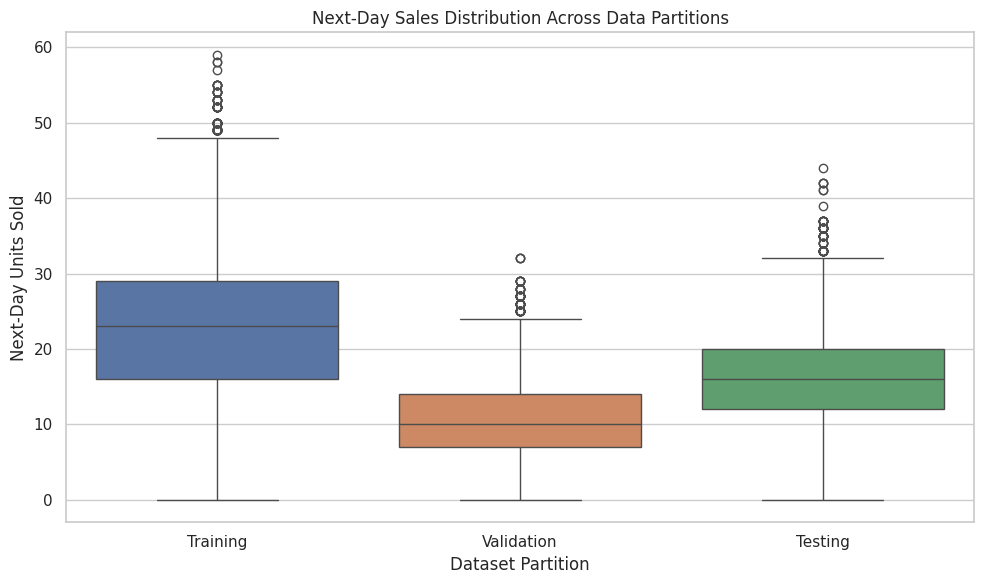

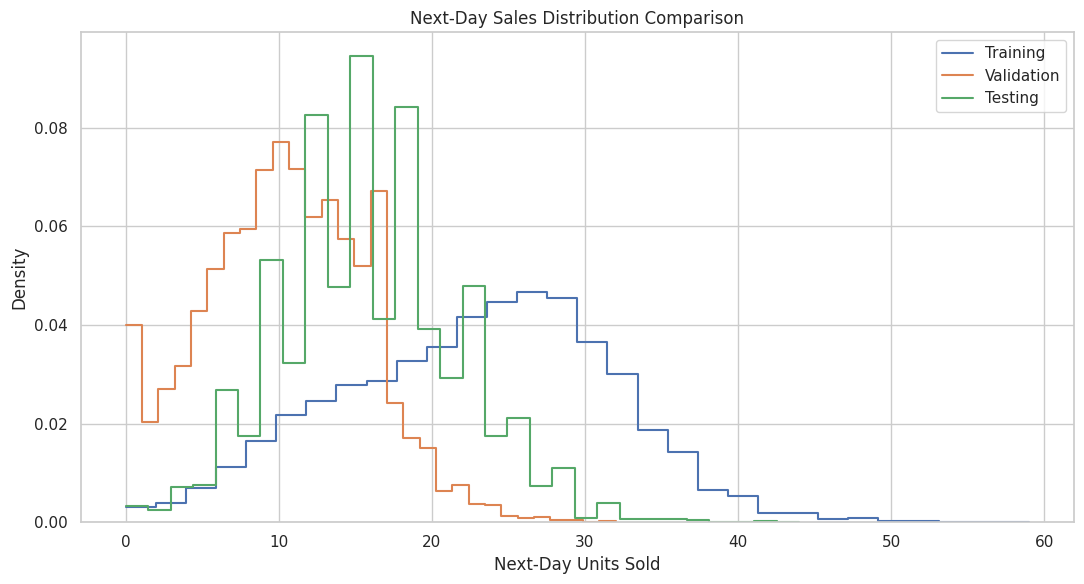

In [12]:
# STEP 8C: COMPARE TARGET DISTRIBUTIONS ACROSS DATA PARTITIONS

# Create a dictionary containing the target values for each partition.
target_partitions = {
    "Training": y_train,
    "Validation": y_validation,
    "Testing": y_test
}

# Create an empty list to store descriptive statistics.
target_distribution_results = []

# Calculate descriptive statistics for each partition.
for partition_name, target_values in target_partitions.items():

    # Calculate the main distribution statistics.
    target_distribution_results.append({
        "Dataset": partition_name,
        "Count": target_values.count(),
        "Mean": target_values.mean(),
        "Median": target_values.median(),
        "Standard_Deviation": target_values.std(),
        "Minimum": target_values.min(),
        "Maximum": target_values.max(),
        "Zero_Sales_Count": (target_values == 0).sum(),
        "Zero_Sales_Percentage": (
            (target_values == 0).mean() * 100
        )
    })

# Convert the results into a DataFrame.
target_distribution_summary = pd.DataFrame(
    target_distribution_results
)

# Display the descriptive statistics.
print("TARGET DISTRIBUTION BY PARTITION")
print("=" * 70)

display(target_distribution_summary)

# Create a boxplot to compare the target distributions.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=pd.DataFrame({
        "Training": y_train.reset_index(drop=True),
        "Validation": y_validation.reset_index(drop=True),
        "Testing": y_test.reset_index(drop=True)
    })
)

plt.title("Next-Day Sales Distribution Across Data Partitions")
plt.xlabel("Dataset Partition")
plt.ylabel("Next-Day Units Sold")
plt.tight_layout()
plt.show()

# Create histograms to compare the target distributions.
plt.figure(figsize=(11, 6))

for partition_name, target_values in target_partitions.items():

    # Plot the distribution using the same bin boundaries.
    sns.histplot(
        target_values,
        bins=30,
        stat="density",
        element="step",
        fill=False,
        label=partition_name
    )

plt.title("Next-Day Sales Distribution Comparison")
plt.xlabel("Next-Day Units Sold")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()



# Step 8: Baseline Forecasting Models

## Objective

Establish simple reference models against which machine-learning models can be evaluated.

## Baseline 1: Training Mean

The training mean baseline predicts the average `Units_Sold` observed in the training dataset for every validation observation.

This provides a simple reference point that does not use individual historical sales patterns.

## Baseline 2: Last Observed Sales

The persistence baseline uses `Sales_Lag_1` as the prediction for next-day sales.

It assumes that the most recently observed daily sales value is a reasonable estimate of the following day's sales.

## Evaluation Metrics

Both baselines will be evaluated using:

- Mean Absolute Error (MAE).
- Root Mean Squared Error (RMSE).
- Coefficient of Determination (R²).

The validation dataset will be used for this comparison. The testing dataset remains reserved for final model evaluation.

## Interpretation

More advanced models should be evaluated against both baselines. Lower MAE and RMSE indicate smaller prediction errors. R² provides an additional measure of explained variation, but should not be interpreted in isolation.


In [13]:
# STEP 8B: TRAIN AND EVALUATE BASELINE FORECASTING MODELS

# Define the actual validation target values.
y_validation_actual = validation_df[
    "Target_Next_Day_Units_Sold"
]

# ------------------------------------------------------------
# BASELINE 1: TRAINING MEAN
# ------------------------------------------------------------

# Create a baseline model that always predicts the
# mean target value from the training dataset.
mean_baseline = DummyRegressor(
    strategy="mean"
)

# Fit the baseline using the training target.
# No predictor variables are required for this baseline.
mean_baseline.fit(
    np.zeros((len(train_df), 1)),
    train_df["Target_Next_Day_Units_Sold"]
)

# Generate predictions for the validation observations.
mean_baseline_predictions = mean_baseline.predict(
    np.zeros((len(validation_df), 1))
)

# ------------------------------------------------------------
# BASELINE 2: LAST OBSERVED SALES
# ------------------------------------------------------------

# Use the most recently observed sales as the next-day prediction.
# Sales_Lag_1 is available at the forecast origin.
persistence_baseline_predictions = (
    validation_df["Sales_Lag_1"].to_numpy()
)

# ------------------------------------------------------------
# DEFINE A COMMON EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_regression_model(actual, predicted, model_name):
    """
    Calculate standard regression evaluation metrics.

    Parameters:
        actual: Actual target values.
        predicted: Model predictions.
        model_name: Name assigned to the model.

    Returns:
        Dictionary containing the evaluation metrics.
    """

    # Calculate mean absolute error.
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # Calculate root mean squared error.
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Calculate coefficient of determination.
    r2 = r2_score(
        actual,
        predicted
    )

    # Return the metrics in a dictionary.
    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# ------------------------------------------------------------
# EVALUATE BOTH BASELINE MODELS
# ------------------------------------------------------------

# Evaluate the training mean baseline.
mean_baseline_results = evaluate_regression_model(
    y_validation_actual,
    mean_baseline_predictions,
    "Training Mean Baseline"
)

# Evaluate the persistence baseline.
persistence_baseline_results = evaluate_regression_model(
    y_validation_actual,
    persistence_baseline_predictions,
    "Last Observed Sales Baseline"
)

# Combine the results into one comparison table.
baseline_results = pd.DataFrame([
    mean_baseline_results,
    persistence_baseline_results
])

# Display the baseline comparison.
print("VALIDATION BASELINE MODEL COMPARISON")
print("=" * 70)

display(
    baseline_results.sort_values(
        "MAE"
    ).reset_index(drop=True)
)

# Display the mean prediction used by the first baseline.
print("\nTRAINING TARGET MEAN")
print("=" * 70)

print(
    train_df["Target_Next_Day_Units_Sold"].mean()
)

# Display the average actual sales in the validation dataset.
print("\nVALIDATION TARGET MEAN")
print("=" * 70)

print(
    y_validation_actual.mean()
)

VALIDATION BASELINE MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Last Observed Sales Baseline,5.7883,7.2589,-0.9934
1,Training Mean Baseline,12.3228,13.3072,-5.6993



TRAINING TARGET MEAN
22.7288

VALIDATION TARGET MEAN
10.454901960784314



# Step 9: Investigating Temporal Changes in the Target Variable

## Objective

Investigate the substantial difference between the training and validation target means.

The training target mean is 22.73 units, while the validation target mean is 10.45 units.

## Investigation Areas

1. Compare target-variable distributions across the training and validation periods.
2. Examine average daily sales over time.
3. Compare average target values by SKU and warehouse.
4. Verify that target dates and target values are correctly aligned within each SKU-warehouse group.

## Importance

A substantial change in the target distribution may indicate temporal distribution shift.

If this difference is genuine, a model trained on earlier observations may not generalise well to later observations.

The investigation will distinguish between temporal changes, differences in group composition, and possible data-preparation errors.

No model selection decision will be made until these checks are complete.


TARGET DISTRIBUTION COMPARISON


,Training,Validation
count,"58,750.0000","12,750.0000"
mean,22.7288,10.4549
std,8.9047,5.1415
min,0.0000,0.0000
25%,16.0000,7.0000
50%,23.0000,10.0000
75%,29.0000,14.0000
max,59.0000,32.0000



TARGET MEAN DIFFERENCE
Absolute difference: 12.2739
Percentage decrease: 54.00%

TARGET VALUE FREQUENCIES


,Training_Count,Validation_Count
Target_Next_Day_Units_Sold,,
0.0000,230,356.0000
1.0000,134,188.0000
2.0000,190,276.0000
3.0000,260,368.0000
4.0000,326,430.0000
5.0000,476,584.0000
6.0000,570,698.0000
7.0000,719,799.0000
8.0000,830,809.0000


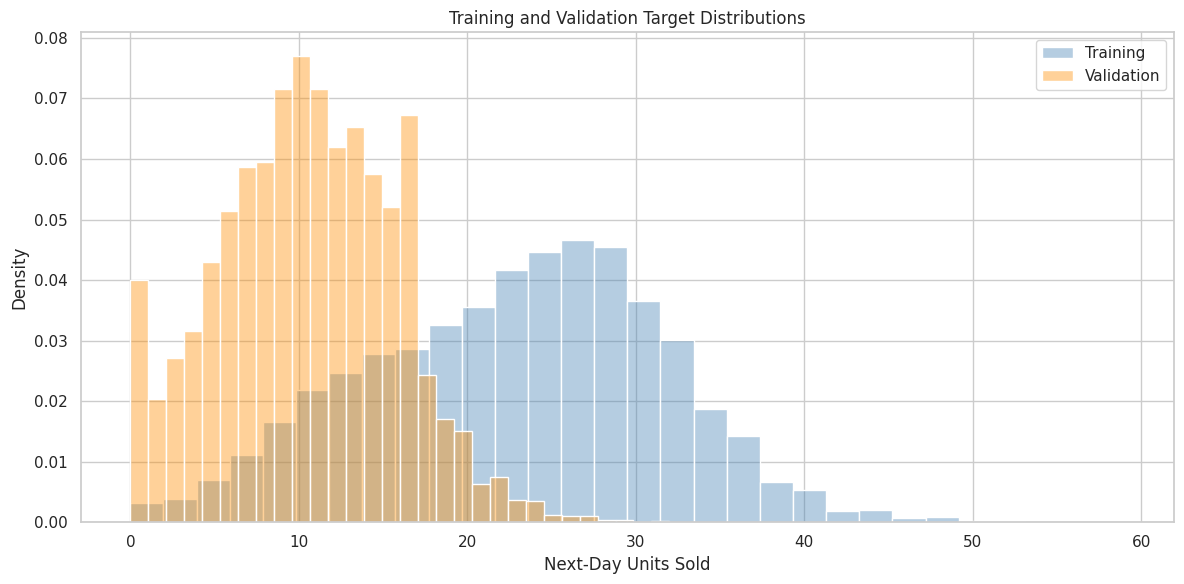

In [14]:
# STEP 9B: COMPARE TRAINING AND VALIDATION TARGET DISTRIBUTIONS

# Define the target variable for both partitions.
training_target = train_df["Target_Next_Day_Units_Sold"]
validation_target = validation_df["Target_Next_Day_Units_Sold"]

# Create a descriptive summary for each partition.
target_distribution_summary = pd.DataFrame({
    "Training": training_target.describe(),
    "Validation": validation_target.describe()
})

# Calculate the difference between the two target means.
mean_difference = (
    training_target.mean() - validation_target.mean()
)

# Calculate the percentage difference relative to the training mean.
percentage_difference = (
    mean_difference / training_target.mean()
) * 100

# Display the distribution comparison.
print("TARGET DISTRIBUTION COMPARISON")
print("=" * 70)
display(target_distribution_summary)

# Display the difference between the means.
print("\nTARGET MEAN DIFFERENCE")
print("=" * 70)
print(f"Absolute difference: {mean_difference:.4f}")
print(f"Percentage decrease: {percentage_difference:.2f}%")

# Compare the frequency of individual sales values.
print("\nTARGET VALUE FREQUENCIES")
print("=" * 70)

target_frequency_comparison = pd.DataFrame({
    "Training_Count": training_target.value_counts().sort_index(),
    "Validation_Count": validation_target.value_counts().sort_index()
}).fillna(0)

display(target_frequency_comparison.head(20))

# Plot the target distributions using comparable histograms.
plt.figure(figsize=(12, 6))

sns.histplot(
    training_target,
    bins=30,
    stat="density",
    color="steelblue",
    alpha=0.4,
    label="Training"
)

sns.histplot(
    validation_target,
    bins=30,
    stat="density",
    color="darkorange",
    alpha=0.4,
    label="Validation"
)

plt.title("Training and Validation Target Distributions")
plt.xlabel("Next-Day Units Sold")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

DAILY SALES SUMMARY BY PARTITION


,Average_Daily_Sales,Minimum_Daily_Sales,Maximum_Daily_Sales,Number_of_Dates
Dataset,,,,
Testing,15.9595,12.0840,20.0920,51
Training,22.7288,9.3240,30.8080,235
Validation,10.4549,9.1760,12.5960,51


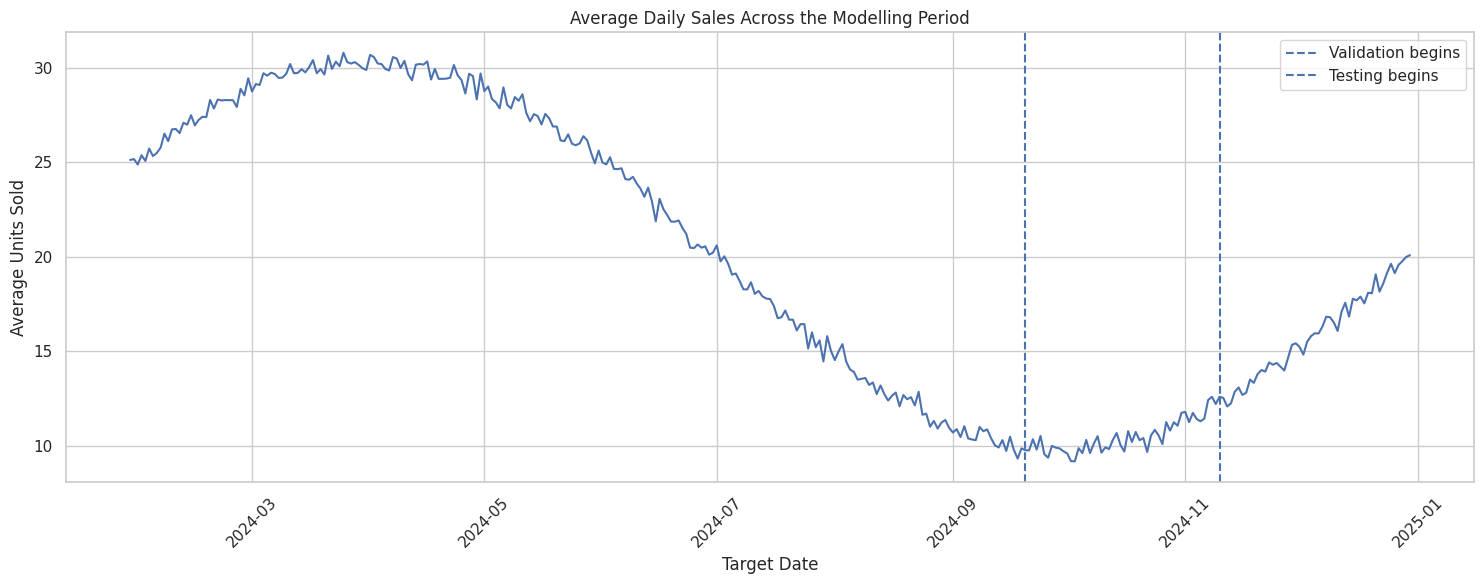

In [15]:
# STEP 9C: EXAMINE DAILY TARGET MEANS OVER TIME

# Calculate the average target value for each target date.
daily_target_summary = (
    df_model.groupby("Target_Date")
    .agg(
        Average_Daily_Sales=(
            "Target_Next_Day_Units_Sold",
            "mean"
        ),
        Total_Daily_Sales=(
            "Target_Next_Day_Units_Sold",
            "sum"
        ),
        Number_of_Observations=(
            "Target_Next_Day_Units_Sold",
            "count"
        )
    )
    .reset_index()
)

# Assign each target date to its corresponding data partition.
daily_target_summary["Dataset"] = np.select(
    [
        daily_target_summary["Target_Date"].isin(train_dates),
        daily_target_summary["Target_Date"].isin(validation_dates),
        daily_target_summary["Target_Date"].isin(test_dates)
    ],
    [
        "Training",
        "Validation",
        "Testing"
    ],
    default="Unassigned"
)

# Display average daily sales by partition.
print("DAILY SALES SUMMARY BY PARTITION")
print("=" * 70)

display(
    daily_target_summary.groupby("Dataset")
    .agg(
        Average_Daily_Sales=("Average_Daily_Sales", "mean"),
        Minimum_Daily_Sales=("Average_Daily_Sales", "min"),
        Maximum_Daily_Sales=("Average_Daily_Sales", "max"),
        Number_of_Dates=("Target_Date", "nunique")
    )
)

# Plot average daily sales over time.
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_target_summary,
    x="Target_Date",
    y="Average_Daily_Sales"
)

plt.axvline(
    validation_df["Target_Date"].min(),
    linestyle="--",
    label="Validation begins"
)

plt.axvline(
    test_df["Target_Date"].min(),
    linestyle="--",
    label="Testing begins"
)

plt.title("Average Daily Sales Across the Modelling Period")
plt.xlabel("Target Date")
plt.ylabel("Average Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# STEP 9D: COMPARE SALES BY SKU-WAREHOUSE GROUP

# Calculate average target sales for each SKU-warehouse group
# separately in the training and validation partitions.
group_target_comparison = (
    df_model.groupby(
        ["SKU_ID", "Warehouse_ID", "SKU_Warehouse_Group"]
    )
    .apply(
        lambda group: pd.Series({
            "Training_Mean": group.loc[
                group["Target_Date"].isin(train_dates),
                "Target_Next_Day_Units_Sold"
            ].mean(),
            "Validation_Mean": group.loc[
                group["Target_Date"].isin(validation_dates),
                "Target_Next_Day_Units_Sold"
            ].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

# Calculate the change in average sales for each group.
group_target_comparison["Mean_Difference"] = (
    group_target_comparison["Validation_Mean"]
    - group_target_comparison["Training_Mean"]
)

# Calculate the number of groups with lower validation averages.
groups_with_lower_validation_sales = (
    group_target_comparison["Mean_Difference"] < 0
).sum()

# Calculate the number of groups with higher validation averages.
groups_with_higher_validation_sales = (
    group_target_comparison["Mean_Difference"] > 0
).sum()

# Display the group-level comparison summary.
print("SKU-WAREHOUSE GROUP COMPARISON")
print("=" * 70)

print("Number of groups:", len(group_target_comparison))
print(
    "Groups with lower validation averages:",
    groups_with_lower_validation_sales
)
print(
    "Groups with higher validation averages:",
    groups_with_higher_validation_sales
)

display(
    group_target_comparison[
        [
            "Training_Mean",
            "Validation_Mean",
            "Mean_Difference"
        ]
    ].describe()
)

# Display the five groups with the largest decreases.
print("\nFIVE LARGEST DECREASES")
print("=" * 70)

display(
    group_target_comparison.nsmallest(
        5,
        "Mean_Difference"
    )
)

# Display the five groups with the largest increases.
print("\nFIVE LARGEST INCREASES")
print("=" * 70)

display(
    group_target_comparison.nlargest(
        5,
        "Mean_Difference"
    )
)

SKU-WAREHOUSE GROUP COMPARISON
Number of groups: 250
Groups with lower validation averages: 250
Groups with higher validation averages: 0


,Training_Mean,Validation_Mean,Mean_Difference
count,250.0000,250.0000,250.0000
mean,22.7288,10.4549,-12.2739
std,0.3395,0.7065,0.7843
min,21.6894,7.7059,-14.6814
25%,22.4989,10.0392,-12.8055
50%,22.7106,10.4902,-12.2408
75%,22.9521,10.9951,-11.6781
max,23.7660,12.0784,-10.3641



FIVE LARGEST DECREASES


,SKU_ID,Warehouse_ID,SKU_Warehouse_Group,Training_Mean,Validation_Mean,Mean_Difference
179,SKU_41,WH_5,SKU_41_WH_5,22.3872,7.7059,-14.6814
56,SKU_2,WH_2,SKU_2_WH_2,23.0553,8.5098,-14.5455
172,SKU_40,WH_3,SKU_40_WH_3,22.7489,8.5490,-14.1999
170,SKU_40,WH_1,SKU_40_WH_1,23.1021,9.0392,-14.0629
212,SKU_48,WH_3,SKU_48_WH_3,23.1319,9.1961,-13.9358



FIVE LARGEST INCREASES


,SKU_ID,Warehouse_ID,SKU_Warehouse_Group,Training_Mean,Validation_Mean,Mean_Difference
139,SKU_34,WH_5,SKU_34_WH_5,22.4426,12.0784,-10.3641
224,SKU_5,WH_5,SKU_5_WH_5,22.1787,11.6863,-10.4924
98,SKU_27,WH_4,SKU_27_WH_4,22.4000,11.8235,-10.5765
115,SKU_30,WH_1,SKU_30_WH_1,22.5574,11.6863,-10.8712
208,SKU_47,WH_4,SKU_47_WH_4,22.4596,11.5686,-10.8909


In [17]:
# STEP 9E: VERIFY NEXT-DAY TARGET ALIGNMENT

# Create a fresh copy of the original sorted dataset.
alignment_check = df.copy()

# Recreate the next-day target independently.
alignment_check["Expected_Next_Day_Target"] = (
    alignment_check.groupby("SKU_Warehouse_Group")["Units_Sold"]
    .shift(-1)
)

# Recreate the expected next target date independently.
alignment_check["Expected_Target_Date"] = (
    alignment_check.groupby("SKU_Warehouse_Group")["Date"]
    .shift(-1)
)

# Match the independently calculated target values
# to the existing engineered modelling dataset.
alignment_check = alignment_check.merge(
    df_model[
        [
            "SKU_Warehouse_Group",
            "Date",
            "Target_Next_Day_Units_Sold",
            "Target_Date"
        ]
    ],
    on=["SKU_Warehouse_Group", "Date"],
    how="inner"
)

# Compare the expected and engineered target values.
target_alignment_correct = (
    alignment_check["Expected_Next_Day_Target"]
    == alignment_check["Target_Next_Day_Units_Sold"]
).all()

# Compare the expected and engineered target dates.
date_alignment_correct = (
    alignment_check["Expected_Target_Date"]
    == alignment_check["Target_Date"]
).all()

# Display the alignment validation results.
print("TARGET ALIGNMENT VALIDATION")
print("=" * 70)

print("Target values correctly aligned:", target_alignment_correct)
print("Target dates correctly aligned:", date_alignment_correct)
print("Observations checked:", len(alignment_check))

TARGET ALIGNMENT VALIDATION
Target values correctly aligned: True
Target dates correctly aligned: True
Observations checked: 84250



### Step 9F: Investigating the Timing of the Sales Distribution Shift

**Research question:** When did the observed decline in daily sales occur, and was it gradual or concentrated within a particular period?

**Methodology:**
- Calculate average next-day sales for each target date.
- Calculate 7-day and 28-day rolling averages to smooth daily fluctuations.
- Summarise average sales by calendar month.
- Compare the timing of the observed trends with the chronological training, validation and testing periods.

**Purpose:** Determine whether the change in the target distribution appears gradual, abrupt or temporary.

**Limitation:** Temporal patterns alone cannot establish the cause of a sales decline.


In [18]:

# STEP 9F.1: Examine daily and monthly sales trends

# Calculate average target sales for each target date.
daily_sales_trend = (
    df_model.groupby("Target_Date")["Target_Next_Day_Units_Sold"]
    .agg(["mean", "median", "std", "count"])
    .reset_index()
)

# Rename columns for readability.
daily_sales_trend.columns = [
    "Target_Date",
    "Average_Sales",
    "Median_Sales",
    "Sales_Standard_Deviation",
    "Observation_Count"
]

# Sort observations chronologically.
daily_sales_trend = daily_sales_trend.sort_values("Target_Date")

# Calculate rolling averages using calendar-day observations.
daily_sales_trend["Rolling_Mean_7_Days"] = (
    daily_sales_trend["Average_Sales"].rolling(window=7).mean()
)

daily_sales_trend["Rolling_Mean_28_Days"] = (
    daily_sales_trend["Average_Sales"].rolling(window=28).mean()
)

# Display the first and last observations.
print("FIRST 10 DAILY OBSERVATIONS")
display(daily_sales_trend.head(10))

print("\nLAST 10 DAILY OBSERVATIONS")
display(daily_sales_trend.tail(10))

# Calculate monthly average sales.
daily_sales_trend["Month"] = (
    daily_sales_trend["Target_Date"].dt.to_period("M").astype(str)
)

monthly_sales_trend = (
    daily_sales_trend.groupby("Month")
    .agg(
        Average_Daily_Sales=("Average_Sales", "mean"),
        Minimum_Daily_Sales=("Average_Sales", "min"),
        Maximum_Daily_Sales=("Average_Sales", "max"),
        Number_of_Dates=("Target_Date", "count")
    )
    .reset_index()
)

print("\nMONTHLY DAILY-SALES SUMMARY")
display(monthly_sales_trend.round(4))


FIRST 10 DAILY OBSERVATIONS


,Target_Date,Average_Sales,Median_Sales,Sales_Standard_Deviation,Observation_Count,Rolling_Mean_7_Days,Rolling_Mean_28_Days
0,2024-01-29,25.1360,25.0000,5.7244,250,NaN,NaN
1,2024-01-30,25.1800,25.0000,5.5395,250,NaN,NaN
2,2024-01-31,24.8920,25.0000,5.2900,250,NaN,NaN
3,2024-02-01,25.3840,25.5000,5.9695,250,NaN,NaN
4,2024-02-02,25.0800,25.0000,5.6719,250,NaN,NaN
5,2024-02-03,25.7360,25.5000,5.6164,250,NaN,NaN
6,2024-02-04,25.3400,25.0000,6.0141,250,25.2497,NaN
7,2024-02-05,25.5040,25.0000,5.7135,250,25.3023,NaN
8,2024-02-06,25.7840,26.0000,5.5538,250,25.3886,NaN
9,2024-02-07,26.5240,27.0000,5.2620,250,25.6217,NaN



LAST 10 DAILY OBSERVATIONS


,Target_Date,Average_Sales,Median_Sales,Sales_Standard_Deviation,Observation_Count,Rolling_Mean_7_Days,Rolling_Mean_28_Days
327,2024-12-21,19.0760,19.0000,5.2226,250,18.0269,16.2799
328,2024-12-22,18.1640,18.0000,4.9350,250,18.0806,16.4180
329,2024-12-23,18.6080,18.0000,5.5608,250,18.2097,16.5687
330,2024-12-24,19.1680,19.0000,5.5192,250,18.3909,16.7466
331,2024-12-25,19.6360,19.0000,5.3974,250,18.6903,16.9483
332,2024-12-26,19.1400,19.0000,5.2725,250,18.8383,17.1080
333,2024-12-27,19.5800,20.0000,5.4761,250,19.0531,17.2593
334,2024-12-28,19.7760,19.0000,5.6920,250,19.1531,17.4146
335,2024-12-29,20.0000,20.0000,5.9103,250,19.4154,17.5847
336,2024-12-30,20.0920,20.0000,5.2239,250,19.6274,17.7727



MONTHLY DAILY-SALES SUMMARY


,Month,Average_Daily_Sales,Minimum_Daily_Sales,Maximum_Daily_Sales,Number_of_Dates
0,2024-01,25.0693,24.8920,25.1800,3
1,2024-02,27.1983,25.0800,29.4560,29
2,2024-03,29.8834,28.7560,30.8080,31
3,2024-04,29.8391,28.3360,30.6960,30
4,2024-05,27.2053,24.9520,29.0240,31
5,2024-06,22.6684,20.1200,25.2800,30
6,2024-07,17.4084,14.4680,20.6120,31
7,2024-08,12.7766,10.9160,15.3840,31
8,2024-09,10.1739,9.3240,11.0400,30
9,2024-10,10.2708,9.1760,11.7480,31


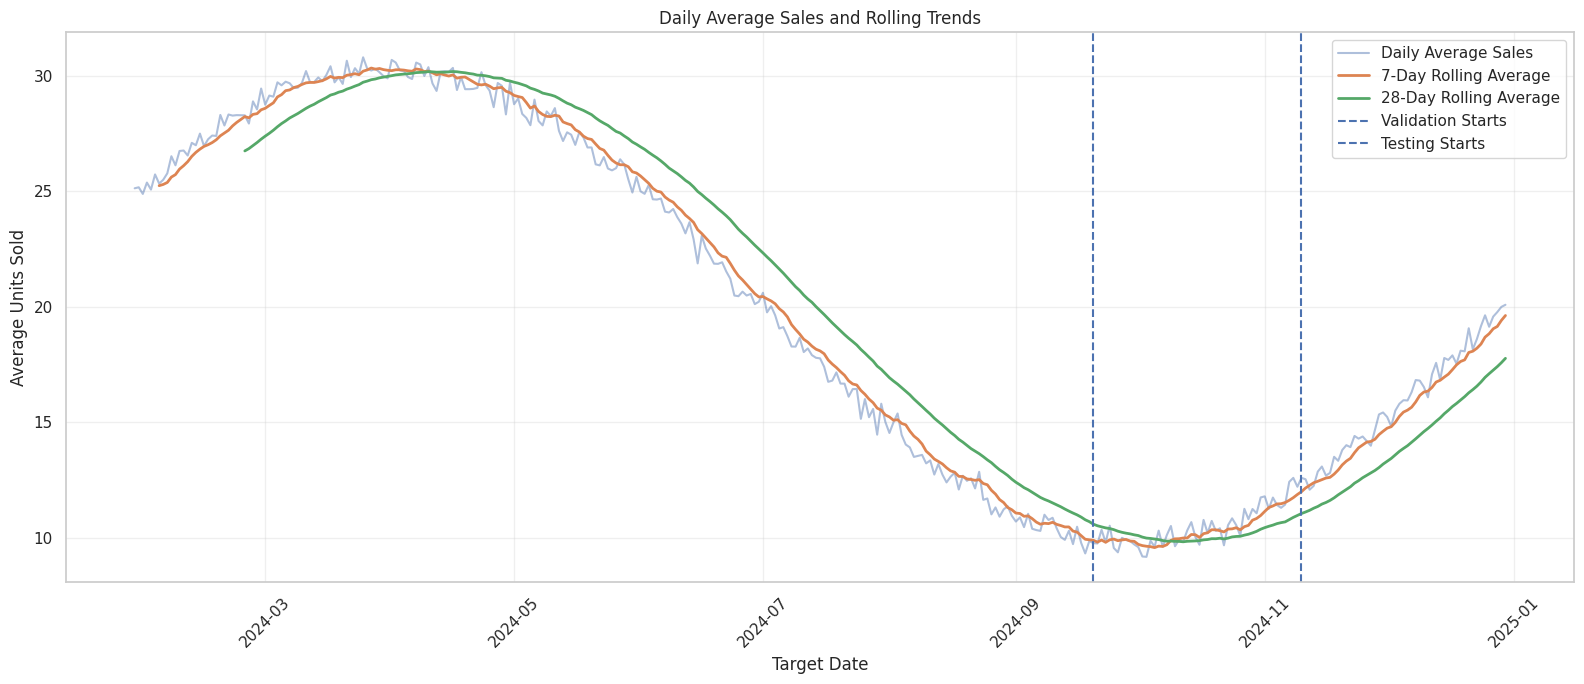

In [19]:

# STEP 9F.2: Visualise the daily sales trend

plt.figure(figsize=(16, 7))

# Plot daily average sales.
plt.plot(
    daily_sales_trend["Target_Date"],
    daily_sales_trend["Average_Sales"],
    label="Daily Average Sales",
    alpha=0.45
)

# Plot the 7-day rolling average.
plt.plot(
    daily_sales_trend["Target_Date"],
    daily_sales_trend["Rolling_Mean_7_Days"],
    label="7-Day Rolling Average",
    linewidth=2
)

# Plot the 28-day rolling average.
plt.plot(
    daily_sales_trend["Target_Date"],
    daily_sales_trend["Rolling_Mean_28_Days"],
    label="28-Day Rolling Average",
    linewidth=2
)

# Mark the chronological partition boundaries.
plt.axvline(
    pd.Timestamp("2024-09-20"),
    linestyle="--",
    label="Validation Starts"
)

plt.axvline(
    pd.Timestamp("2024-11-10"),
    linestyle="--",
    label="Testing Starts"
)

plt.title("Daily Average Sales and Rolling Trends")
plt.xlabel("Target Date")
plt.ylabel("Average Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

# STEP 9F.3: Identify the largest changes between consecutive dates

# Calculate the change in daily average sales.
daily_sales_trend["Daily_Change"] = (
    daily_sales_trend["Average_Sales"].diff()
)

# Calculate the absolute size of each change.
daily_sales_trend["Absolute_Daily_Change"] = (
    daily_sales_trend["Daily_Change"].abs()
)

# Identify the five largest increases and decreases.
largest_increases = (
    daily_sales_trend.nlargest(5, "Daily_Change")
)

largest_decreases = (
    daily_sales_trend.nsmallest(5, "Daily_Change")
)

print("FIVE LARGEST DAILY INCREASES")
display(
    largest_increases[
        ["Target_Date", "Average_Sales", "Daily_Change"]
    ].round(4)
)

print("\nFIVE LARGEST DAILY DECREASES")
display(
    largest_decreases[
        ["Target_Date", "Average_Sales", "Daily_Change"]
    ].round(4)
)


FIVE LARGEST DAILY INCREASES


,Target_Date,Average_Sales,Daily_Change
92,2024-04-30,29.7120,1.3760
183,2024-07-30,15.8080,1.3400
139,2024-06-16,23.0760,1.1920
272,2024-10-27,11.2560,1.1640
98,2024-05-06,28.9760,1.1080



FIVE LARGEST DAILY DECREASES


,Target_Date,Average_Sales,Daily_Change
178,2024-07-25,15.1520,-1.2920
91,2024-04-29,28.3360,-1.2360
208,2024-08-24,11.6440,-1.2160
182,2024-07-29,14.4680,-1.1120
138,2024-06-15,21.8840,-1.0440



### Step 9G: Monthly Sales Trends and Temporal Distribution Shift

**Research question:** How did average daily sales change across the calendar months of 2024, and how do these changes relate to the training, validation and testing periods?

**Methodology:**
- Calculate monthly average daily sales across all SKU-warehouse groups.
- Calculate monthly minimum and maximum daily averages.
- Identify the chronological partition associated with each target date.
- Visualise monthly sales trends and compare the three partitions.

**Purpose:** Determine whether the observed distribution shift is concentrated in particular months or reflects a broader temporal pattern.

**Limitations:**
- Monthly averages can conceal daily fluctuations.
- One year of observations cannot establish recurring annual seasonality.
- Descriptive comparisons do not establish the cause of changes in demand.


In [21]:

# STEP 9G.2: Calculate monthly average daily sales

# Work with a copy of the daily sales summary.
monthly_analysis = daily_sales_trend.copy()

# Assign each target date to its chronological partition.
monthly_analysis["Dataset"] = np.select(
    [
        monthly_analysis["Target_Date"] < pd.Timestamp("2024-09-20"),
        monthly_analysis["Target_Date"] < pd.Timestamp("2024-11-10")
    ],
    [
        "Training",
        "Validation"
    ],
    default="Testing"
)

# Extract the calendar month.
monthly_analysis["Month"] = (
    monthly_analysis["Target_Date"].dt.month
)

# Calculate monthly descriptive statistics.
monthly_summary = (
    monthly_analysis.groupby("Month")
    .agg(
        Average_Daily_Sales=("Average_Sales", "mean"),
        Minimum_Daily_Sales=("Average_Sales", "min"),
        Maximum_Daily_Sales=("Average_Sales", "max"),
        Daily_Sales_Std=("Average_Sales", "std"),
        Number_of_Dates=("Target_Date", "count")
    )
    .reset_index()
)

# Add month names for readability.
monthly_summary["Month_Name"] = (
    pd.to_datetime(monthly_summary["Month"], format="%m")
    .dt.month_name()
)

# Display the results chronologically.
monthly_summary = monthly_summary[
    [
        "Month",
        "Month_Name",
        "Average_Daily_Sales",
        "Minimum_Daily_Sales",
        "Maximum_Daily_Sales",
        "Daily_Sales_Std",
        "Number_of_Dates"
    ]
]

print("MONTHLY DAILY-SALES SUMMARY")
display(monthly_summary.round(4))


MONTHLY DAILY-SALES SUMMARY


,Month,Month_Name,Average_Daily_Sales,Minimum_Daily_Sales,Maximum_Daily_Sales,Daily_Sales_Std,Number_of_Dates
0,1,January,25.0693,24.8920,25.1800,0.1551,3
1,2,February,27.1983,25.0800,29.4560,1.1813,29
2,3,March,29.8834,28.7560,30.8080,0.4395,31
3,4,April,29.8391,28.3360,30.6960,0.5507,30
4,5,May,27.2053,24.9520,29.0240,1.1201,31
5,6,June,22.6684,20.1200,25.2800,1.6714,30
6,7,July,17.4084,14.4680,20.6120,1.6051,31
7,8,August,12.7766,10.9160,15.3840,1.1983,31
8,9,September,10.1739,9.3240,11.0400,0.4812,30
9,10,October,10.2708,9.1760,11.7480,0.6212,31


In [22]:

# STEP 9G.3: Compare monthly average sales by partition

# Calculate average daily sales for each month and partition.
monthly_partition_summary = (
    monthly_analysis.groupby(["Month", "Dataset"])
    .agg(
        Average_Daily_Sales=("Average_Sales", "mean"),
        Number_of_Dates=("Target_Date", "count")
    )
    .reset_index()
)

# Display the monthly comparison.
print("MONTHLY SALES BY CHRONOLOGICAL PARTITION")
display(
    monthly_partition_summary.round(4)
)


MONTHLY SALES BY CHRONOLOGICAL PARTITION


,Month,Dataset,Average_Daily_Sales,Number_of_Dates
0,1,Training,25.0693,3
1,2,Training,27.1983,29
2,3,Training,29.8834,31
3,4,Training,29.8391,30
4,5,Training,27.2053,31
5,6,Training,22.6684,30
6,7,Training,17.4084,31
7,8,Training,12.7766,31
8,9,Training,10.3474,19
9,9,Validation,9.8742,11


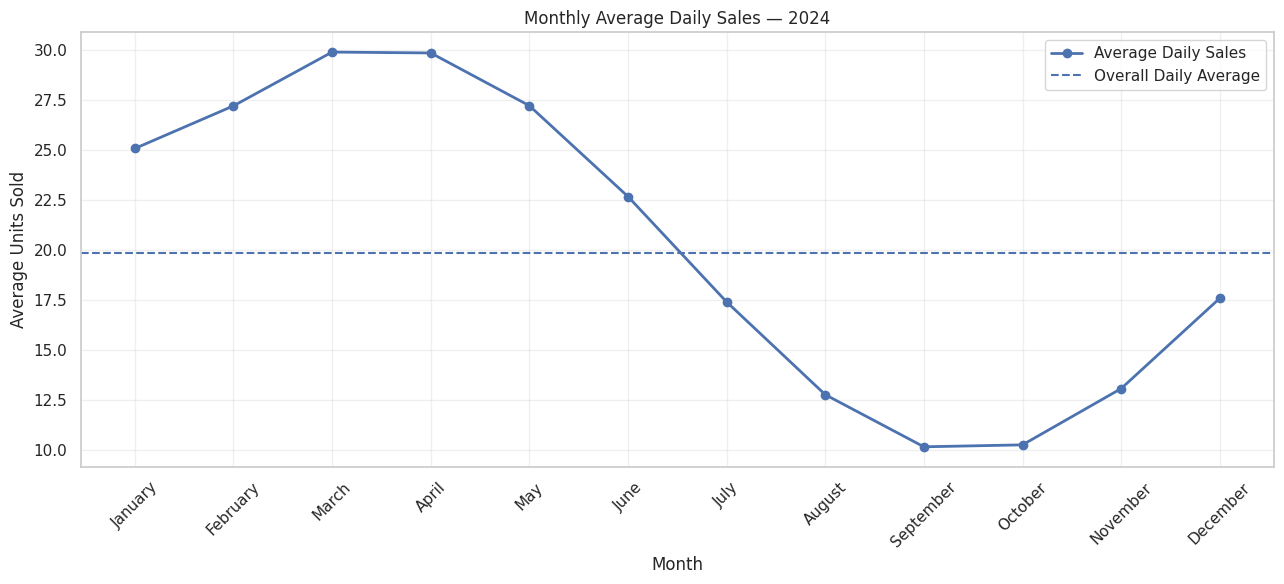

In [23]:

# STEP 9G.4: Plot monthly average daily sales

plt.figure(figsize=(13, 6))

# Plot the monthly average daily sales.
plt.plot(
    monthly_summary["Month_Name"],
    monthly_summary["Average_Daily_Sales"],
    marker="o",
    linewidth=2,
    label="Average Daily Sales"
)

# Add a reference line for the overall average.
overall_daily_average = daily_sales_trend["Average_Sales"].mean()

plt.axhline(
    overall_daily_average,
    linestyle="--",
    label="Overall Daily Average"
)

plt.title("Monthly Average Daily Sales — 2024")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Step 9H: Conclusion — Temporal Sales Distribution Shift

The investigation identified a substantial change in average daily sales during 2024.

**Key findings:**

1. Average daily sales increased from 25.07 units in January to approximately 29.88 units in March.
2. Average daily sales subsequently declined, reaching approximately 10.17 units in September.
3. Sales remained relatively low in October, averaging 10.27 units.
4. A partial recovery occurred in November and December, reaching 17.59 units in December.
5. All 250 SKU-warehouse groups experienced lower average sales during validation than during training.
6. Target values and target dates passed the independent alignment checks.

**Interpretation:**

The training, validation and testing partitions represent different periods within a changing demand environment. The poor performance of the training-mean baseline is partly explained by the difference in average sales between the training and validation periods.

The pattern is consistent with a temporal change in demand levels. However, the available observations do not establish the underlying cause.

**Modelling implications:**

- Preserve chronological data splitting.
- Avoid random shuffling.
- Compare models against persistence and weekly seasonal-naive baselines.
- Evaluate whether recent sales history improves forecasting performance.
- Monitor performance across different periods rather than relying exclusively on one aggregate metric.
- Avoid claiming that one year of data establishes recurring annual seasonality.

**Conclusion:**

The dataset presents a meaningful forecasting challenge because the observed sales distribution changes over time. Predictive models must be evaluated under these temporal conditions rather than assuming that historical sales patterns remain constant.


In [24]:

# STEP 9H.2: Compare four baseline forecasting approaches

# Baseline 1: Predict the average target sales in the training dataset.
training_mean = y_train.mean()

baseline_predictions = {
    "Training Mean": np.full(
        len(y_validation),
        training_mean
    ),

    # Baseline 2: Predict tomorrow's sales using today's observed sales.
    "Persistence": X_validation["Sales_Lag_1"].to_numpy(),

    # Baseline 3: Predict tomorrow's sales using sales from seven days earlier.
    "Weekly Seasonal Naive": X_validation["Sales_Lag_7"].to_numpy(),

    # Baseline 4: Predict tomorrow's sales using the latest seven-day average.
    "Seven-Day Rolling Mean": X_validation["Rolling_Mean_7"].to_numpy()
}

# Store the actual validation target values.
actual_values = y_validation.to_numpy()

# Calculate evaluation metrics for every baseline.
baseline_results = []

for model_name, predictions in baseline_predictions.items():

    # Calculate mean absolute error.
    mae = mean_absolute_error(
        actual_values,
        predictions
    )

    # Calculate root mean squared error.
    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predictions
        )
    )

    # Calculate coefficient of determination.
    r2 = r2_score(
        actual_values,
        predictions
    )

    # Calculate mean forecast error.
    # Positive values indicate overforecasting.
    mean_error = np.mean(
        predictions - actual_values
    )

    baseline_results.append({
        "Baseline": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Mean_Forecast_Error": mean_error
    })

# Convert results into a DataFrame.
baseline_comparison = pd.DataFrame(
    baseline_results
)

# Sort by MAE, with the lowest error first.
baseline_comparison = baseline_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("VALIDATION BASELINE COMPARISON")
display(
    baseline_comparison.round(4)
)


VALIDATION BASELINE COMPARISON


,Baseline,MAE,RMSE,R2,Mean_Forecast_Error
0,Seven-Day Rolling Mean,4.3433,5.4353,-0.1177,-0.1734
1,Weekly Seasonal Naive,5.7506,7.1878,-0.9545,-0.2695
2,Persistence,5.7883,7.2589,-0.9934,-0.0460
3,Training Mean,12.3228,13.3072,-5.6993,12.2739



### Baseline Forecasting Methods

Four baseline forecasting methods are evaluated using the validation dataset.

| Baseline | Forecasting approach |
|---|---|
| Training Mean | Uses the average target sales in the training dataset |
| Persistence | Uses the current day's sales as the next day's forecast |
| Weekly Seasonal Naive | Uses sales observed seven calendar days before the target date |
| Seven-Day Rolling Mean | Uses the average sales across the seven most recent observations available at the forecast origin |

**Evaluation metrics:**

- MAE measures average absolute forecast error.
- RMSE penalises larger forecast errors more heavily.
- R² measures predictive performance relative to the validation target mean.
- Mean Forecast Error measures systematic overforecasting or underforecasting.

**Evaluation principle:**

All baselines use information available at the forecast origin. No future target observations are used to generate predictions.



### Step 9H: Baseline Forecasting Results and Conclusion

Four baseline forecasting methods were evaluated using 12,750 validation observations.

**Results:**

| Baseline | MAE | RMSE | R² |
|---|---:|---:|---:|
| Seven-Day Rolling Mean | 4.3433 | 5.4353 | -0.1177 |
| Weekly Seasonal Naive | 5.7506 | 7.1878 | -0.9545 |
| Persistence | 5.7883 | 7.2589 | -0.9934 |
| Training Mean | 12.3228 | 13.3072 | -5.6993 |

**Key findings:**

1. The seven-day rolling mean achieved the lowest MAE and RMSE.
2. Its MAE was approximately 25% lower than the persistence baseline.
3. All four baselines produced negative R² values.
4. The training-mean baseline performed particularly poorly because of the temporal difference between training and validation sales levels.

**Modelling decision:**

The seven-day rolling mean is selected as the primary benchmark for machine-learning models.

Future models must be evaluated on the same validation observations and compared against this benchmark.

**Limitations:**

The results represent validation performance for this particular chronological split. They do not establish how the models will perform under all future demand conditions.



## Step 10: Machine-Learning Model Development

**Objective:** Develop supervised machine-learning models to forecast next-day units sold for each SKU-warehouse combination.

**Target variable:**
- Target_Next_Day_Units_Sold

**Predictor variables:**
- Recent sales observations and lag features.
- Rolling sales averages.
- Calendar features.
- SKU, warehouse and supplier identifiers.

**Candidate models:**
1. Linear Regression.
2. Random Forest Regressor.

**Preprocessing:**
- One-hot encode categorical identifiers.
- Retain numerical predictors in their appropriate numerical format.
- Use a consistent preprocessing pipeline for each model.
- Ignore previously unseen categories during prediction.

**Evaluation strategy:**
- Fit models using training observations only.
- Use validation observations for model comparison.
- Retain the chronological testing observations for final evaluation.
- Compare model performance against the seven-day rolling-mean benchmark.

**Important:** No random train-test shuffling will be performed because this is a time-dependent forecasting problem.


In [25]:

# STEP 10.2: Inspect predictor data types and categorical variables

# Identify categorical predictor columns.
categorical_features = [
    "SKU_ID",
    "Warehouse_ID",
    "Supplier_ID"
]

# Identify numerical predictor columns.
numerical_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

# Display the training predictor data types.
print("TRAINING PREDICTOR DATA TYPES")
display(X_train.dtypes.to_frame("Data_Type"))

# Display the categorical feature values.
print("\nCATEGORICAL FEATURE COUNTS")

for column in categorical_features:

    # Count distinct categories in the training dataset.
    print(
        column,
        ":",
        X_train[column].nunique(),
        "unique categories"
    )

# Display the numerical feature names.
print("\nNUMERICAL FEATURES")
print(numerical_features)

# Check whether any predictor values are missing.
print("\nMISSING VALUES")

print(
    "Training:",
    X_train.isnull().sum().sum()
)

print(
    "Validation:",
    X_validation.isnull().sum().sum()
)

print(
    "Testing:",
    X_test.isnull().sum().sum()
)


TRAINING PREDICTOR DATA TYPES


,Data_Type
Sales_Lag_1,int64
Sales_Lag_7,float64
Sales_Lag_14,float64
Sales_Lag_28,float64
Rolling_Mean_7,float64
Rolling_Mean_14,float64
Rolling_Mean_28,float64
Target_Is_Weekend,int64
SKU_ID,object
Warehouse_ID,object



CATEGORICAL FEATURE COUNTS
SKU_ID : 50 unique categories
Warehouse_ID : 5 unique categories
Supplier_ID : 10 unique categories

NUMERICAL FEATURES
['Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Lag_28', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_28', 'Target_Is_Weekend', 'Target_Day_of_Week', 'Target_Month']

MISSING VALUES
Training: 0
Validation: 0
Testing: 0



### Step 10.3: Machine-Learning Preprocessing

A preprocessing pipeline is established to prepare the predictors for machine-learning model development.

**Categorical preprocessing:**
- SKU_ID
- Warehouse_ID
- Supplier_ID
- One-hot encoding is applied to prevent identifiers from being interpreted as numerical quantities.
- Unknown categories are ignored during transformation.

**Numerical preprocessing:**
- Linear Regression: numerical predictors are standardised.
- Random Forest: numerical predictors retain their original scales.

**Data leakage prevention:**

All preprocessing transformations are fitted using training data only. The fitted transformations are subsequently applied to validation data without refitting.

**Purpose:** Ensure that both candidate models receive appropriately transformed predictors while preserving the chronological evaluation design.


In [26]:

# STEP 10.3.1: Import machine-learning preprocessing tools

# Import the column transformation utility.
from sklearn.compose import ColumnTransformer

# Import categorical and numerical preprocessing tools.
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Import pipeline functionality.
from sklearn.pipeline import Pipeline

# Import the candidate regression models.
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Confirm that the required tools are available.
print("Preprocessing and modelling libraries imported successfully.")


Preprocessing and modelling libraries imported successfully.


In [27]:

# STEP 10.3.2: Configure preprocessing for both candidate models

# Configure categorical preprocessing.
# Unknown categories will be ignored during validation and testing.
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Configure numerical preprocessing for Linear Regression.
numerical_transformer_linear = StandardScaler()

# Combine categorical and numerical preprocessing for Linear Regression.
preprocessor_linear = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer_linear,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

# Configure preprocessing for Random Forest.
# Numerical variables do not require standardisation for this model.
preprocessor_forest = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Confirm the preprocessing configurations.
print("Linear Regression preprocessor:")
print(preprocessor_linear)

print("\nRandom Forest preprocessor:")
print(preprocessor_forest)


Linear Regression preprocessor:
ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                 ['Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14',
                                  'Sales_Lag_28', 'Rolling_Mean_7',
                                  'Rolling_Mean_14', 'Rolling_Mean_28',
                                  'Target_Is_Weekend', 'Target_Day_of_Week',
                                  'Target_Month']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['SKU_ID', 'Warehouse_ID', 'Supplier_ID'])])

Random Forest preprocessor:
ColumnTransformer(transformers=[('numerical', 'passthrough',
                                 ['Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14',
                                  'Sales_Lag_28', 'Rolling_Mean_7',
                                  'Rolling_Mean_14', 'Rolling_Mean_28',
                                  'Target_Is_W


### Step 10.4: Initial Machine-Learning Model Training

Two supervised regression models are developed:

**Model 1: Linear Regression**
- Establishes a linear relationship between predictors and next-day sales.
- Uses standardised numerical predictors and one-hot encoded categorical predictors.

**Model 2: Random Forest Regressor**
- Captures potentially nonlinear relationships and interactions.
- Uses 300 decision trees.
- Uses a minimum of two observations per leaf to introduce some regularisation.

**Training procedure:**
- Both models are fitted using the training dataset only.
- Validation data is used for performance evaluation.
- The testing dataset remains untouched.

**Important:** These are initial configurations. Hyperparameter optimisation and further model diagnostics will follow if justified by validation results.


In [28]:

# STEP 10.4.1: Build and train the Linear Regression model

# Create a pipeline containing preprocessing and Linear Regression.
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_linear
        ),
        (
            "regressor",
            LinearRegression()
        )
    ]
)

# Fit the complete pipeline using training data only.
linear_model.fit(
    X_train,
    y_train
)

# Confirm successful training.
print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


In [29]:

# STEP 10.4.2: Train a computationally lighter Random Forest model

# Configure a smaller Random Forest model.
random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create the preprocessing and modelling pipeline.
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_forest
        ),
        (
            "regressor",
            random_forest
        )
    ]
)

# Train the model using training observations only.
random_forest_model.fit(
    X_train,
    y_train
)

# Confirm successful training.
print("Revised Random Forest model trained successfully.")


Revised Random Forest model trained successfully.


In [30]:

# STEP 10.5.1: Generate validation predictions for both models

# Generate predictions using the trained Linear Regression model.
linear_predictions = linear_model.predict(X_validation)

# Generate predictions using the trained Random Forest model.
random_forest_predictions = random_forest_model.predict(X_validation)

# Define a reusable function to calculate regression metrics.
def evaluate_regression_model(actual, predicted, model_name):

    # Calculate Mean Absolute Error.
    mae = mean_absolute_error(actual, predicted)

    # Calculate Root Mean Squared Error.
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Calculate the coefficient of determination.
    r2 = r2_score(actual, predicted)

    # Calculate Mean Forecast Error.
    # Positive values indicate underforecasting.
    # Negative values indicate overforecasting.
    mfe = np.mean(actual - predicted)

    # Return the evaluation results.
    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MFE": mfe
    }

# Evaluate both models on the same validation observations.
validation_results = pd.DataFrame([
    evaluate_regression_model(
        y_validation,
        linear_predictions,
        "Linear Regression"
    ),
    evaluate_regression_model(
        y_validation,
        random_forest_predictions,
        "Random Forest"
    )
])

# Display the comparison.
print("VALIDATION MODEL PERFORMANCE")
print("=" * 70)

display(
    validation_results.round(4)
)


VALIDATION MODEL PERFORMANCE


,Model,MAE,RMSE,R2,MFE
0,Linear Regression,4.8630,6.0768,-0.3970,2.9998
1,Random Forest,4.1606,5.1934,-0.0204,0.1529



## 10.5 Validation Evaluation of Predictive Models

### Objective
Evaluate the predictive performance of Linear Regression and Random Forest using the validation dataset.

### Evaluation approach
Both models are evaluated against the same validation observations to ensure a fair comparison.

The following metrics are calculated:

- **MAE:** Average absolute prediction error. Lower values indicate better accuracy.
- **RMSE:** Penalises larger prediction errors more heavily. Lower values indicate better performance.
- **R²:** Measures the proportion of target variation explained relative to predicting the validation mean.
- **MFE:** Measures signed prediction error. Positive values indicate underforecasting, while negative values indicate overforecasting.

### Model selection
The results will be compared with the seven-day rolling-mean benchmark:

- Benchmark MAE: 4.3433
- Benchmark RMSE: 5.4353
- Benchmark R²: -0.1177

The validation results will guide model selection. The testing dataset will remain unused until the final model has been selected.



## 10.5.2 Interpretation of Validation Model Performance

### Model comparison

The Linear Regression and Random Forest models were evaluated using the same chronological validation dataset.

Random Forest achieved the following results:

- MAE: 4.1606
- RMSE: 5.1934
- R²: -0.0204
- MFE: 0.1529

Linear Regression achieved:

- MAE: 4.8630
- RMSE: 6.0768
- R²: -0.3970
- MFE: 2.9998

### Comparison against the baseline

The seven-day rolling-mean benchmark achieved an MAE of 4.3433 and RMSE of 5.4353.

Random Forest improved on this benchmark by approximately:

- 4.21% in MAE.
- 4.45% in RMSE.

Linear Regression did not outperform the benchmark.

### Interpretation

Random Forest currently demonstrates the strongest validation performance among the three approaches.

Its lower MAE and RMSE indicate improved prediction accuracy compared with both Linear Regression and the seven-day rolling-mean benchmark.

Its MFE of 0.1529 indicates a small average underforecast.

However, its negative R² value indicates that it has not yet outperformed the validation-set mean predictor in terms of squared-error performance.

The improvement over the rolling-mean benchmark is also relatively modest.

### Preliminary conclusion

Random Forest is the leading candidate for further evaluation, but it will not yet be declared the final model.

Further investigation will examine prediction errors across calendar months and different demand levels.

The testing dataset remains untouched.


In [31]:

# STEP 10.5.3: Compare validation performance across target months

# Create a detailed validation results DataFrame.
validation_predictions_df = pd.DataFrame(
    {
        "Target_Date": df_model.loc[
            X_validation.index,
            "Target_Date"
        ].values,

        "Actual_Sales": y_validation.values,

        "Linear_Regression_Predictions": linear_predictions,

        "Random_Forest_Predictions": random_forest_predictions
    }
)

# Convert target dates to datetime format.
validation_predictions_df["Target_Date"] = pd.to_datetime(
    validation_predictions_df["Target_Date"]
)

# Extract the calendar month.
validation_predictions_df["Month"] = (
    validation_predictions_df["Target_Date"].dt.month
)

# Calculate absolute prediction errors for both models.
validation_predictions_df["Linear_Regression_Absolute_Error"] = (
    np.abs(
        validation_predictions_df["Actual_Sales"]
        - validation_predictions_df["Linear_Regression_Predictions"]
    )
)

validation_predictions_df["Random_Forest_Absolute_Error"] = (
    np.abs(
        validation_predictions_df["Actual_Sales"]
        - validation_predictions_df["Random_Forest_Predictions"]
    )
)

# Calculate monthly performance metrics.
monthly_model_performance = (
    validation_predictions_df
    .groupby("Month")
    .agg(
        Observations=("Actual_Sales", "count"),

        Average_Actual_Sales=("Actual_Sales", "mean"),

        Linear_Regression_MAE=(
            "Linear_Regression_Absolute_Error",
            "mean"
        ),

        Random_Forest_MAE=(
            "Random_Forest_Absolute_Error",
            "mean"
        )
    )
    .reset_index()
)

# Calculate the percentage improvement of Random Forest over Linear Regression.
monthly_model_performance["RF_MAE_Improvement_Percent"] = (
    (
        monthly_model_performance["Linear_Regression_MAE"]
        - monthly_model_performance["Random_Forest_MAE"]
    )
    / monthly_model_performance["Linear_Regression_MAE"]
) * 100

# Display the monthly comparison.
print("MONTHLY VALIDATION MODEL PERFORMANCE")
print("=" * 85)

display(
    monthly_model_performance.round(4)
)


MONTHLY VALIDATION MODEL PERFORMANCE


,Month,Observations,Average_Actual_Sales,Linear_Regression_MAE,Random_Forest_MAE,RF_MAE_Improvement_Percent
0,1,114,10.5351,4.7368,4.0871,13.7157
1,2,1102,10.5771,4.9297,4.1565,15.6835
2,3,1178,10.2564,4.7929,4.2409,11.5167
3,4,1140,10.3982,4.7535,4.0801,14.1662
4,5,1178,10.3981,4.8109,4.1546,13.6413
5,6,1140,10.0342,4.8218,4.1951,12.9970
6,7,1178,10.4508,4.9622,4.2818,13.7119
7,8,1178,10.6409,4.8480,3.9661,18.1916
8,9,1140,10.5482,4.9161,4.2614,13.3179
9,10,1178,10.6299,4.9254,4.1573,15.5949


In [32]:

# STEP 10.5.4: Verify validation prediction and target-date alignment

# Retrieve target dates using the validation feature indices.
validation_target_dates = df_model.loc[
    X_validation.index,
    "Target_Date"
]

# Display the validation date range.
print("VALIDATION TARGET DATE RANGE")
print("=" * 60)

print("First target date:", validation_target_dates.min())
print("Last target date:", validation_target_dates.max())

# Display the unique calendar months represented.
print("\nVALIDATION MONTHS")
print("=" * 60)

print(
    sorted(
        validation_target_dates.dt.month.unique()
    )
)

# Count observations by month.
print("\nVALIDATION OBSERVATIONS BY MONTH")
print("=" * 60)

display(
    validation_target_dates.dt.month
    .value_counts()
    .sort_index()
    .rename("Observations")
    .to_frame()
)

# Verify that the retrieved dates match the prediction table.
print("\nDATE ALIGNMENT CHECK")
print("=" * 60)

print(
    "Dates match prediction table:",
    np.array_equal(
        validation_target_dates.to_numpy(),
        validation_predictions_df["Target_Date"].to_numpy()
    )
)

print(
    "Validation observation count:",
    len(X_validation)
)

print(
    "Prediction table observation count:",
    len(validation_predictions_df)
)


VALIDATION TARGET DATE RANGE
First target date: 2024-01-29 00:00:00
Last target date: 2024-12-30 00:00:00

VALIDATION MONTHS
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

VALIDATION OBSERVATIONS BY MONTH


,Observations
Target_Date,
1,114
2,1102
3,1178
4,1140
5,1178
6,1140
7,1178
8,1178
9,1140



DATE ALIGNMENT CHECK
Dates match prediction table: True
Validation observation count: 12750
Prediction table observation count: 12750


In [34]:
df_model.loc[X_validation.index, "Target_Date"]

,Target_Date
0,2024-01-29
1,2024-01-30
2,2024-01-31
3,2024-02-01
4,2024-02-02
...,...
12745,2024-10-31
12746,2024-11-01
12747,2024-11-02
12748,2024-11-03


In [36]:

# STEP 10.5.5: Reconstruct and verify the validation dataset

# Define the established validation target-date boundaries.
validation_start = pd.Timestamp("2024-09-20")
validation_end = pd.Timestamp("2024-11-09")

# Reconstruct validation rows using their actual target dates.
validation_rows_correct = df_model.loc[
    df_model["Target_Date"].between(
        validation_start,
        validation_end
    )
].copy()

# Reset indices to allow positional comparison.
validation_rows_correct = validation_rows_correct.reset_index(drop=True)

X_validation_check = X_validation.reset_index(drop=True)
y_validation_check = y_validation.reset_index(drop=True)

# Reconstruct predictors in their original column order.
X_validation_reconstructed = validation_rows_correct[
    X_validation.columns
].reset_index(drop=True)

# Compare numerical columns using numerical tolerance.
numerical_columns = X_validation.select_dtypes(
    include=["number"]
).columns.tolist()

numerical_match = np.allclose(
    X_validation_reconstructed[numerical_columns].to_numpy(),
    X_validation_check[numerical_columns].to_numpy(),
    equal_nan=True
)

# Compare categorical columns directly.
categorical_columns = X_validation.select_dtypes(
    exclude=["number"]
).columns.tolist()

categorical_match = (
    X_validation_reconstructed[categorical_columns]
    .equals(X_validation_check[categorical_columns])
)

# Compare reconstructed target values.
targets_match = np.allclose(
    validation_rows_correct["Target_Next_Day_Units_Sold"].to_numpy(),
    y_validation_check.to_numpy()
)

# Display reconstruction results.
print("VALIDATION DATASET RECONSTRUCTION")
print("=" * 65)

print("Reconstructed observations:", len(validation_rows_correct))
print("Expected validation observations:", len(X_validation))

print(
    "First target date:",
    validation_rows_correct["Target_Date"].min()
)

print(
    "Last target date:",
    validation_rows_correct["Target_Date"].max()
)

print("Numerical predictors match:", numerical_match)
print("Categorical predictors match:", categorical_match)
print("Target values match:", targets_match)

# Display monthly observation counts.
print("\nOBSERVATIONS BY TARGET MONTH")
print("=" * 65)

display(
    validation_rows_correct["Target_Date"]
    .dt.month
    .value_counts()
    .sort_index()
    .rename("Observations")
    .to_frame()
)


VALIDATION DATASET RECONSTRUCTION
Reconstructed observations: 12750
Expected validation observations: 12750
First target date: 2024-09-20 00:00:00
Last target date: 2024-11-09 00:00:00
Numerical predictors match: True
Categorical predictors match: True
Target values match: True

OBSERVATIONS BY TARGET MONTH


,Observations
Target_Date,
9,2750
10,7750
11,2250


In [37]:

# STEP 10.5.6: Recalculate monthly validation model performance

# Create a fresh validation prediction table using verified target dates.
monthly_validation_df = pd.DataFrame(
    {
        "Target_Date": validation_rows_correct["Target_Date"],
        "Actual_Sales": y_validation_check,
        "Linear_Regression_Predictions": linear_predictions,
        "Random_Forest_Predictions": random_forest_predictions
    }
)

# Extract the target calendar month.
monthly_validation_df["Month"] = (
    monthly_validation_df["Target_Date"].dt.month
)

# Calculate absolute prediction errors for both models.
monthly_validation_df["Linear_Regression_Absolute_Error"] = (
    np.abs(
        monthly_validation_df["Actual_Sales"]
        - monthly_validation_df["Linear_Regression_Predictions"]
    )
)

monthly_validation_df["Random_Forest_Absolute_Error"] = (
    np.abs(
        monthly_validation_df["Actual_Sales"]
        - monthly_validation_df["Random_Forest_Predictions"]
    )
)

# Calculate monthly performance metrics.
corrected_monthly_performance = (
    monthly_validation_df
    .groupby("Month")
    .agg(
        Observations=("Actual_Sales", "count"),
        Average_Actual_Sales=("Actual_Sales", "mean"),
        Linear_Regression_MAE=(
            "Linear_Regression_Absolute_Error", "mean"
        ),
        Random_Forest_MAE=(
            "Random_Forest_Absolute_Error", "mean"
        )
    )
    .reset_index()
)

# Calculate Random Forest's percentage MAE improvement over Linear Regression.
corrected_monthly_performance[
    "RF_MAE_Improvement_Percent"
] = (
    (
        corrected_monthly_performance["Linear_Regression_MAE"]
        - corrected_monthly_performance["Random_Forest_MAE"]
    )
    / corrected_monthly_performance["Linear_Regression_MAE"]
) * 100

# Display the corrected monthly results.
print("CORRECTED MONTHLY VALIDATION PERFORMANCE")
print("=" * 85)

display(
    corrected_monthly_performance.round(4)
)

# Reconcile overall MAE values against the earlier evaluation.
print("\nOVERALL MAE RECONCILIATION")
print("=" * 85)

print(
    "Linear Regression MAE:",
    round(
        mean_absolute_error(
            y_validation_check,
            linear_predictions
        ),
        4
    )
)

print(
    "Random Forest MAE:",
    round(
        mean_absolute_error(
            y_validation_check,
            random_forest_predictions
        ),
        4
    )
)


CORRECTED MONTHLY VALIDATION PERFORMANCE


,Month,Observations,Average_Actual_Sales,Linear_Regression_MAE,Random_Forest_MAE,RF_MAE_Improvement_Percent
0,9,2750,9.8742,4.1449,4.0463,2.3793
1,10,7750,10.2708,4.7887,4.1431,13.4826
2,11,2250,11.7987,5.9967,4.3605,27.2849



OVERALL MAE RECONCILIATION
Linear Regression MAE: 4.863
Random Forest MAE: 4.1606



## 10.5.7 Corrected Monthly Validation Performance

### Objective
Examine whether the validation performance of Random Forest is consistent across the three calendar months represented in the validation dataset.

### Data alignment verification
The validation dataset was independently reconstructed using the target-date boundaries.

The following checks passed:

- Reconstructed observations: 12,750.
- First target date: 2024-09-20.
- Last target date: 2024-11-09.
- Numerical predictors matched: True.
- Categorical predictors matched: True.
- Target values matched: True.

### Monthly results

| Month | Observations | Linear Regression MAE | Random Forest MAE | RF improvement |
|---|---:|---:|---:|---:|
| September | 2,750 | 4.1449 | 4.0463 | 2.38% |
| October | 7,750 | 4.7887 | 4.1431 | 13.48% |
| November | 2,250 | 5.9967 | 4.3605 | 27.28% |

### Interpretation

Random Forest achieved a lower MAE than Linear Regression in all three validation months.

The performance advantage increased from September through November.

Linear Regression experienced a substantial increase in prediction error in November, whereas Random Forest demonstrated a smaller increase.

These results suggest that Random Forest handled the changing demand conditions in the validation period more effectively than Linear Regression.

### Limitations

The validation period covers only three calendar months from one year of observations.

The results do not establish that Random Forest will consistently outperform other forecasting methods in future periods.

The comparison is observational and does not establish the causes of the differences in predictive performance.

### Preliminary conclusion

Random Forest remains the leading candidate based on the overall and monthly validation results.

Final model selection will also consider its performance against the seven-day rolling-mean benchmark.


In [38]:

# STEP 10.5.8: Compare Random Forest against the rolling-mean benchmark

# Use the seven-day rolling mean as the benchmark prediction.
monthly_validation_df["Rolling_Mean_7_Predictions"] = (
    X_validation_check["Rolling_Mean_7"].to_numpy()
)

# Calculate absolute errors for the rolling-mean benchmark.
monthly_validation_df["Rolling_Mean_7_Absolute_Error"] = (
    np.abs(
        monthly_validation_df["Actual_Sales"]
        - monthly_validation_df["Rolling_Mean_7_Predictions"]
    )
)

# Calculate monthly MAE for all three approaches.
benchmark_monthly_performance = (
    monthly_validation_df
    .groupby("Month")
    .agg(
        Observations=("Actual_Sales", "count"),
        Rolling_Mean_7_MAE=(
            "Rolling_Mean_7_Absolute_Error", "mean"
        ),
        Linear_Regression_MAE=(
            "Linear_Regression_Absolute_Error", "mean"
        ),
        Random_Forest_MAE=(
            "Random_Forest_Absolute_Error", "mean"
        )
    )
    .reset_index()
)

# Calculate Random Forest improvement over the rolling-mean benchmark.
benchmark_monthly_performance[
    "RF_Improvement_vs_Rolling_Mean_Percent"
] = (
    (
        benchmark_monthly_performance["Rolling_Mean_7_MAE"]
        - benchmark_monthly_performance["Random_Forest_MAE"]
    )
    / benchmark_monthly_performance["Rolling_Mean_7_MAE"]
) * 100

# Display the three-model monthly comparison.
print("MONTHLY VALIDATION: THREE-MODEL COMPARISON")
print("=" * 95)

display(
    benchmark_monthly_performance.round(4)
)

# Reconcile the rolling-mean benchmark against its previously calculated overall MAE.
print("\nOVERALL ROLLING-MEAN BENCHMARK MAE")
print("=" * 95)

print(
    round(
        mean_absolute_error(
            y_validation_check,
            X_validation_check["Rolling_Mean_7"]
        ),
        4
    )
)


MONTHLY VALIDATION: THREE-MODEL COMPARISON


,Month,Observations,Rolling_Mean_7_MAE,Linear_Regression_MAE,Random_Forest_MAE,RF_Improvement_vs_Rolling_Mean_Percent
0,9,2750,4.2817,4.1449,4.0463,5.4966
1,10,7750,4.3452,4.7887,4.1431,4.6510
2,11,2250,4.4123,5.9967,4.3605,1.1727



OVERALL ROLLING-MEAN BENCHMARK MAE
4.3433



## 10.5.9 Validation-Based Model Selection

### Model comparison

Three forecasting approaches were evaluated using the validation dataset:

1. Seven-Day Rolling Mean benchmark.
2. Linear Regression.
3. Random Forest.

Random Forest achieved the lowest monthly MAE in all three validation months.

| Metric | Seven-Day Rolling Mean | Linear Regression | Random Forest |
|---|---:|---:|---:|
| Overall MAE | 4.3433 | 4.8630 | 4.1606 |
| Overall RMSE | 5.4353 | 6.0768 | 5.1934 |

### Performance improvement

Compared with the seven-day rolling-mean benchmark, Random Forest achieved:

- Approximately 4.21% lower MAE.
- Approximately 4.45% lower RMSE.

Monthly MAE improvement over the rolling-mean benchmark:

- September: 5.50%.
- October: 4.65%.
- November: 1.17%.

### Model selection decision

Random Forest is selected as the leading candidate for final testing.

The selection is supported by its lower overall MAE and RMSE and its consistently lower monthly MAE across the validation period.

However, the improvement over the benchmark is modest, and the Random Forest R² remains slightly negative.

The model should therefore be regarded as a modest improvement over the baseline rather than a highly accurate forecasting solution.

### Testing protocol

The testing dataset has not been used for model selection or hyperparameter tuning.

The selected Random Forest model will now be evaluated on the chronological testing period to assess its performance on observations not used during training or validation.

No further model adjustments will be made based on the testing results.


In [39]:

# STEP 10.6.1: Generate final predictions on the testing dataset

# Generate predictions using the selected Random Forest model.
random_forest_test_predictions = random_forest_model.predict(X_test)

# Generate predictions using Linear Regression for reference.
linear_test_predictions = linear_model.predict(X_test)

# Use the seven-day rolling mean as the test benchmark.
rolling_mean_test_predictions = X_test["Rolling_Mean_7"].to_numpy()

# Calculate and compare final test metrics.
test_results = pd.DataFrame([
    evaluate_regression_model(
        y_test,
        rolling_mean_test_predictions,
        "Seven-Day Rolling Mean"
    ),
    evaluate_regression_model(
        y_test,
        linear_test_predictions,
        "Linear Regression"
    ),
    evaluate_regression_model(
        y_test,
        random_forest_test_predictions,
        "Random Forest"
    )
])

# Display final test performance.
print("FINAL TEST DATASET MODEL PERFORMANCE")
print("=" * 75)

display(
    test_results.round(4)
)

# Calculate Random Forest improvement over the benchmark.
rf_test_mae = mean_absolute_error(
    y_test,
    random_forest_test_predictions
)

benchmark_test_mae = mean_absolute_error(
    y_test,
    rolling_mean_test_predictions
)

rf_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_test_predictions
    )
)

benchmark_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rolling_mean_test_predictions
    )
)

print("\nRANDOM FOREST IMPROVEMENT OVER BENCHMARK")
print("=" * 75)

print(
    "MAE improvement (%):",
    round(
        (benchmark_test_mae - rf_test_mae)
        / benchmark_test_mae * 100,
        2
    )
)

print(
    "RMSE improvement (%):",
    round(
        (benchmark_test_rmse - rf_test_rmse)
        / benchmark_test_rmse * 100,
        2
    )
)


FINAL TEST DATASET MODEL PERFORMANCE


,Model,MAE,RMSE,R2,MFE
0,Seven-Day Rolling Mean,4.5063,5.6986,0.0359,0.6058
1,Linear Regression,7.6764,9.1014,-1.4592,7.2427
2,Random Forest,5.8751,7.2974,-0.5810,4.7115



RANDOM FOREST IMPROVEMENT OVER BENCHMARK
MAE improvement (%): -30.38
RMSE improvement (%): -28.06



## 10.6 Final Model Evaluation on the Testing Dataset

### Objective

Evaluate the selected Random Forest model using the chronological testing dataset.

### Testing period

10 November 2024 to 30 December 2024.

### Evaluation approach

The following approaches are evaluated:

- Seven-Day Rolling Mean benchmark.
- Linear Regression reference model.
- Selected Random Forest model.

The evaluation metrics are:

- Mean Absolute Error (MAE).
- Root Mean Squared Error (RMSE).
- R-squared (R²).
- Mean Forecast Error (MFE).

### Data separation

The testing dataset was excluded from model training, validation-based model selection and hyperparameter tuning.

The selected Random Forest model is evaluated without further adjustment.

### Important forecasting assumption

This project evaluates one-step-ahead daily forecasts.

Historical actual sales observations are used to construct lagged and rolling features for subsequent forecast dates. This represents a daily updating forecasting process rather than a single forecast made many days ahead.

### Interpretation

Final conclusions will be based on the test results, with particular attention to whether Random Forest improves upon the seven-day rolling-mean benchmark.



## 10.6.3 Final Test Results and Model Generalisation

### Final test performance

The three forecasting approaches were evaluated on the chronological testing dataset.

| Model | MAE | RMSE | R² | MFE |
|---|---:|---:|---:|---:|
| Seven-Day Rolling Mean | 4.5063 | 5.6986 | 0.0359 | 0.6058 |
| Linear Regression | 7.6764 | 9.1014 | -1.4592 | 7.2427 |
| Random Forest | 5.8751 | 7.2974 | -0.5810 | 4.7115 |

### Comparison with the benchmark

Random Forest performed worse than the seven-day rolling-mean benchmark:

- MAE was approximately 30.38% higher.
- RMSE was approximately 28.06% higher.

Linear Regression also performed worse than the benchmark.

### Forecast bias

Both machine-learning models produced positive Mean Forecast Errors, indicating underforecasting.

Random Forest had an MFE of 4.7115, while Linear Regression had an MFE of 7.2427.

The rolling-mean benchmark had a substantially smaller MFE of 0.6058.

### Generalisation assessment

Random Forest performed best during validation but failed to maintain that advantage on the independent test dataset.

This indicates that its validation performance did not generalise to the later testing period.

The seven-day rolling-mean benchmark achieved the best test performance among the three approaches.

### Final preliminary conclusion

Based on the independent test results, the seven-day rolling mean is the preferred forecasting approach among the methods evaluated.

Random Forest should not be presented as the winning forecasting model.

The difference between validation and test performance highlights the importance of chronological data splitting and independent testing in time-series forecasting.

No further model adjustments will be made using the test results.


In [40]:

# STEP 10.6.4: Examine demand levels and forecast bias across data partitions

# Create a DataFrame containing test dates, actual sales and predictions.
test_predictions_df = pd.DataFrame(
    {
        "Target_Date": df_model.loc[
            X_test.index,
            "Target_Date"
        ].values,

        "Actual_Sales": y_test.to_numpy(),

        "Rolling_Mean_7_Predictions": rolling_mean_test_predictions,

        "Linear_Regression_Predictions": linear_test_predictions,

        "Random_Forest_Predictions": random_forest_test_predictions
    }
)

# Convert target dates to datetime.
test_predictions_df["Target_Date"] = pd.to_datetime(
    test_predictions_df["Target_Date"]
)

# Extract calendar month.
test_predictions_df["Month"] = (
    test_predictions_df["Target_Date"].dt.month
)

# Calculate the average target sales in each partition.
partition_demand_summary = pd.DataFrame(
    {
        "Partition": [
            "Training",
            "Validation",
            "Testing"
        ],

        "Observations": [
            len(y_train),
            len(y_validation),
            len(y_test)
        ],

        "Average_Actual_Sales": [
            y_train.mean(),
            y_validation.mean(),
            y_test.mean()
        ],

        "Standard_Deviation": [
            y_train.std(),
            y_validation.std(),
            y_test.std()
        ]
    }
)

# Display demand levels across the three chronological partitions.
print("DEMAND LEVELS ACROSS DATA PARTITIONS")
print("=" * 75)

display(
    partition_demand_summary.round(4)
)

# Calculate average predictions and forecast errors on the test dataset.
test_prediction_summary = pd.DataFrame(
    {
        "Series": [
            "Actual Sales",
            "Seven-Day Rolling Mean",
            "Linear Regression",
            "Random Forest"
        ],

        "Average_Value": [
            test_predictions_df["Actual_Sales"].mean(),
            test_predictions_df["Rolling_Mean_7_Predictions"].mean(),
            test_predictions_df["Linear_Regression_Predictions"].mean(),
            test_predictions_df["Random_Forest_Predictions"].mean()
        ]
    }
)

print("\nAVERAGE TEST ACTUALS AND PREDICTIONS")
print("=" * 75)

display(
    test_prediction_summary.round(4)
)

# Calculate monthly test-period performance for descriptive analysis.
test_predictions_df["Random_Forest_Error"] = (
    test_predictions_df["Actual_Sales"]
    - test_predictions_df["Random_Forest_Predictions"]
)

test_predictions_df["Rolling_Mean_Error"] = (
    test_predictions_df["Actual_Sales"]
    - test_predictions_df["Rolling_Mean_7_Predictions"]
)

monthly_test_diagnostics = (
    test_predictions_df
    .groupby("Month")
    .agg(
        Observations=("Actual_Sales", "count"),
        Average_Actual_Sales=("Actual_Sales", "mean"),
        Average_Random_Forest_Prediction=(
            "Random_Forest_Predictions", "mean"
        ),
        Random_Forest_MFE=("Random_Forest_Error", "mean"),
        Random_Forest_MAE=("Random_Forest_Error", lambda x: np.mean(np.abs(x))),
        Rolling_Mean_MFE=("Rolling_Mean_Error", "mean"),
        Rolling_Mean_MAE=("Rolling_Mean_Error", lambda x: np.mean(np.abs(x)))
    )
    .reset_index()
)

print("\nMONTHLY TEST-PERIOD DIAGNOSTICS")
print("=" * 100)

display(
    monthly_test_diagnostics.round(4)
)


DEMAND LEVELS ACROSS DATA PARTITIONS


,Partition,Observations,Average_Actual_Sales,Standard_Deviation
0,Training,58750,22.7288,8.9047
1,Validation,12750,10.4549,5.1415
2,Testing,12750,15.9595,5.8039



AVERAGE TEST ACTUALS AND PREDICTIONS


,Series,Average_Value
0,Actual Sales,15.9595
1,Seven-Day Rolling Mean,15.3536
2,Linear Regression,8.7168
3,Random Forest,11.2480



MONTHLY TEST-PERIOD DIAGNOSTICS


,Month,Observations,Average_Actual_Sales,Average_Random_Forest_Prediction,Random_Forest_MFE,Random_Forest_MAE,Rolling_Mean_MFE,Rolling_Mean_MAE
0,1,114,16.0439,11.2719,4.7720,6.1352,0.6378,4.6604
1,2,1102,16.0118,11.2278,4.7840,5.9986,0.6029,4.6501
2,3,1178,15.8455,11.2398,4.6057,5.8274,0.4985,4.4910
3,4,1140,15.8965,11.2105,4.6860,5.7772,0.7414,4.4175
4,5,1178,15.9686,11.2725,4.6961,5.8140,0.6375,4.5488
5,6,1140,15.9614,11.3167,4.6447,5.7069,0.5170,4.3336
6,7,1178,15.7334,11.1906,4.5429,5.8891,0.5916,4.5753
7,8,1178,15.9508,11.2201,4.7306,5.9325,0.6124,4.5186
8,9,1140,15.9535,11.2750,4.6785,5.8749,0.5893,4.6320
9,10,1178,16.1621,11.2578,4.9044,5.9242,0.6751,4.4175


In [41]:

# STEP 10.6.5: Reconstruct the testing dataset using target dates

# Select observations using the actual chronological testing period.
test_rows_correct = (
    df_model.loc[
        df_model["Target_Date"].between(
            "2024-11-10",
            "2024-12-30"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

# Reconstruct the testing predictors and target in chronological order.
X_test_reconstructed = (
    test_rows_correct[X_test.columns]
    .reset_index(drop=True)
)

y_test_reconstructed = (
    test_rows_correct["Target_Next_Day_Units_Sold"]
    .reset_index(drop=True)
)

# Confirm that the reconstructed observations match the original test data.
print("TEST DATASET RECONSTRUCTION VALIDATION")
print("=" * 75)

print(
    "Correct testing date range:",
    test_rows_correct["Target_Date"].min(),
    "to",
    test_rows_correct["Target_Date"].max()
)

print(
    "Reconstructed observations:",
    len(test_rows_correct)
)

print(
    "Original testing observations:",
    len(X_test)
)

print(
    "Numerical predictors match:",
    np.allclose(
        X_test_reconstructed.select_dtypes(include=np.number).to_numpy(),
        X_test.reset_index(drop=True).select_dtypes(include=np.number).to_numpy()
    )
)

print(
    "Categorical predictors match:",
    X_test_reconstructed.select_dtypes(exclude=np.number).equals(
        X_test.reset_index(drop=True).select_dtypes(exclude=np.number)
    )
)

print(
    "Target values match:",
    np.array_equal(
        y_test_reconstructed.to_numpy(),
        y_test.reset_index(drop=True).to_numpy()
    )
)

# Build a correctly aligned test-results DataFrame.
test_predictions_correct = pd.DataFrame(
    {
        "Target_Date": test_rows_correct["Target_Date"].to_numpy(),
        "Actual_Sales": y_test_reconstructed.to_numpy(),
        "Rolling_Mean_Prediction": rolling_mean_test_predictions,
        "Linear_Regression_Prediction": linear_test_predictions,
        "Random_Forest_Prediction": random_forest_test_predictions
    }
)

# Extract the month from the correctly aligned target dates.
test_predictions_correct["Month"] = (
    test_predictions_correct["Target_Date"].dt.month
)

# Calculate forecast errors using actual minus predicted sales.
test_predictions_correct["Random_Forest_Error"] = (
    test_predictions_correct["Actual_Sales"]
    - test_predictions_correct["Random_Forest_Prediction"]
)

test_predictions_correct["Rolling_Mean_Error"] = (
    test_predictions_correct["Actual_Sales"]
    - test_predictions_correct["Rolling_Mean_Prediction"]
)

# Summarise the correctly aligned monthly test performance.
monthly_test_diagnostics_correct = (
    test_predictions_correct
    .groupby("Month")
    .agg(
        Observations=("Actual_Sales", "count"),
        Average_Actual_Sales=("Actual_Sales", "mean"),
        Average_Random_Forest_Prediction=(
            "Random_Forest_Prediction", "mean"
        ),
        Random_Forest_MFE=("Random_Forest_Error", "mean"),
        Random_Forest_MAE=(
            "Random_Forest_Error",
            lambda x: np.mean(np.abs(x))
        ),
        Rolling_Mean_MFE=("Rolling_Mean_Error", "mean"),
        Rolling_Mean_MAE=(
            "Rolling_Mean_Error",
            lambda x: np.mean(np.abs(x))
        )
    )
    .reset_index()
)

print("\nCORRECTED MONTHLY TEST-PERIOD DIAGNOSTICS")
print("=" * 100)

display(
    monthly_test_diagnostics_correct.round(4)
)

# Confirm that monthly observations reconcile with the complete test dataset.
print("\nMONTHLY OBSERVATION RECONCILIATION")
print("=" * 75)

print(
    "Monthly observations:",
    monthly_test_diagnostics_correct["Observations"].sum()
)

print(
    "Total test observations:",
    len(test_predictions_correct)
)


TEST DATASET RECONSTRUCTION VALIDATION
Correct testing date range: 2024-11-10 00:00:00 to 2024-12-30 00:00:00
Reconstructed observations: 12750
Original testing observations: 12750
Numerical predictors match: True
Categorical predictors match: True
Target values match: True

CORRECTED MONTHLY TEST-PERIOD DIAGNOSTICS


,Month,Observations,Average_Actual_Sales,Average_Random_Forest_Prediction,Random_Forest_MFE,Random_Forest_MAE,Rolling_Mean_MFE,Rolling_Mean_MAE
0,11,5250,13.6301,10.4228,3.2073,4.9929,0.5276,4.5171
1,12,7500,17.5900,11.8256,5.7644,6.4926,0.6606,4.4986



MONTHLY OBSERVATION RECONCILIATION
Monthly observations: 12750
Total test observations: 12750



## 10.6.5 Corrected Test-Period Diagnostics and Forecast Generalisation

### Test-period reconstruction validation

The testing dataset was independently reconstructed using the target-date boundaries.

The reconstruction confirmed:

- Testing period: 10 November 2024 to 30 December 2024.
- Reconstructed observations: 12,750.
- Original testing observations: 12,750.
- Numerical predictors matched: True.
- Categorical predictors matched: True.
- Target values matched: True.
- Monthly observation counts reconciled with the full testing dataset.

The corrected monthly analysis therefore uses the verified target-date alignment.

### Demand levels across chronological partitions

| Partition | Observations | Average Actual Sales | Standard Deviation |
|---|---:|---:|---:|
| Training | 58,750 | 22.7288 | 8.9047 |
| Validation | 12,750 | 10.4549 | 5.1415 |
| Testing | 12,750 | 15.9595 | 5.8039 |

Average demand declined substantially between training and validation, followed by a partial recovery during testing.

The test-period average remained below the training-period average.

### Average test actuals and predictions

| Series | Average Value |
|---|---:|
| Actual Sales | 15.9595 |
| Seven-Day Rolling Mean | 15.3536 |
| Linear Regression | 8.7168 |
| Random Forest | 11.2480 |

The seven-day rolling mean produced an average prediction closest to actual test demand.

Both machine-learning models substantially underpredicted average demand.

### Corrected monthly test-period diagnostics

| Month | Observations | Average Actual Sales | Average Random Forest Prediction | Random Forest MFE | Random Forest MAE | Rolling Mean MFE | Rolling Mean MAE |
|---|---:|---:|---:|---:|---:|---:|---:|
| November | 5,250 | 13.6301 | 10.4228 | 3.2073 | 4.9929 | 0.5276 | 4.5171 |
| December | 7,500 | 17.5900 | 11.8256 | 5.7644 | 6.4926 | 0.6606 | 4.4986 |

Random Forest underforecasted in both months. Its underforecasting increased in December as average actual demand increased.

The rolling-mean benchmark achieved lower MAE in both months and showed relatively stable monthly MAE.

### Interpretation

The Random Forest model achieved better validation performance than the rolling-mean benchmark but failed to maintain that advantage on the independent test dataset.

Its test MAE was approximately 30.38% higher than the benchmark MAE, while its RMSE was approximately 28.06% higher.

The corrected monthly diagnostics show that the model struggled particularly with the increase in demand during December.

The results are consistent with limited adaptation to changing demand levels. However, the precise cause of this underperformance has not been established.

### Final test-period conclusion

Among the three evaluated approaches, the seven-day rolling mean was the strongest forecasting method on the independent testing dataset.

The Random Forest model should not be presented as the winning forecasting solution.

This analysis demonstrates why chronological validation and independent testing are essential: a model that performs well during validation may not generalise to a later period with different demand characteristics.

The test results are retained as an independent evaluation. No model tuning or feature selection will be based on these test results.


In [42]:

# STEP 10.7.1: Extract Random Forest feature importance

# Retrieve the fitted Random Forest regressor from the pipeline.
fitted_random_forest = random_forest_model.named_steps["regressor"]

# Retrieve the fitted preprocessing component.
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

# Obtain the transformed feature names after preprocessing.
transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Extract the feature importance values from the fitted model.
random_forest_importances = (
    fitted_random_forest.feature_importances_
)

# Combine feature names and importance values into a DataFrame.
feature_importance_df = pd.DataFrame(
    {
        "Feature": transformed_feature_names,
        "Importance": random_forest_importances
    }
)

# Sort features from highest to lowest importance.
feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the 20 most important transformed features.
print("TOP 20 RANDOM FOREST FEATURE IMPORTANCES")
print("=" * 75)

display(
    feature_importance_df.head(20).round(4)
)

# Verify that all importance values sum to approximately one.
print("\nTOTAL FEATURE IMPORTANCE")
print("=" * 75)

print(
    round(
        feature_importance_df["Importance"].sum(),
        6
    )
)


TOP 20 RANDOM FOREST FEATURE IMPORTANCES


,Feature,Importance
0,numerical__Target_Month,0.8452
1,numerical__Rolling_Mean_28,0.0329
2,numerical__Rolling_Mean_14,0.0252
3,numerical__Rolling_Mean_7,0.0149
4,numerical__Sales_Lag_28,0.0128
5,numerical__Sales_Lag_14,0.0125
6,numerical__Sales_Lag_7,0.0124
7,numerical__Sales_Lag_1,0.0124
8,numerical__Target_Day_of_Week,0.0066
9,categorical__Warehouse_ID_WH_2,0.0013



TOTAL FEATURE IMPORTANCE
1.0


AGGREGATED RANDOM FOREST FEATURE IMPORTANCE


,Original_Feature,Importance
0,Target_Month,0.8452
1,Rolling_Mean_28,0.0329
2,Rolling_Mean_14,0.0252
3,Rolling_Mean_7,0.0149
4,Sales_Lag_28,0.0128
5,Sales_Lag_14,0.0125
6,Sales_Lag_7,0.0124
7,Sales_Lag_1,0.0124
8,SKU_ID,0.0117
9,Supplier_ID,0.0069


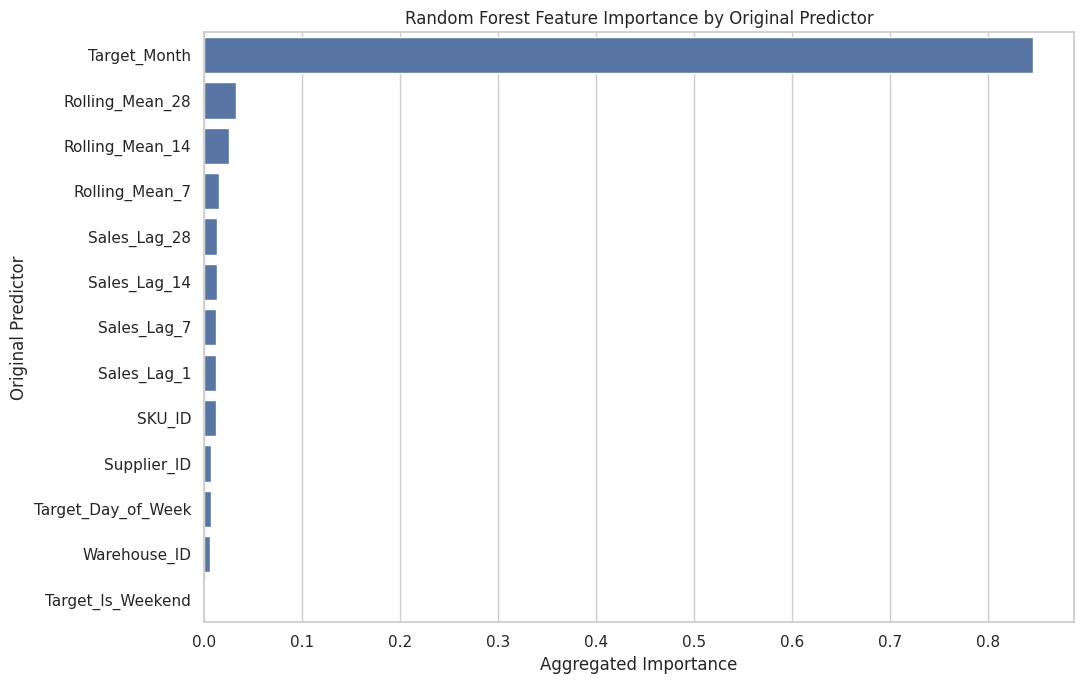

In [43]:

# STEP 10.7.2: Aggregate feature importance by original predictor

# Define the original categorical predictor names.
categorical_feature_names = [
    "SKU_ID",
    "Warehouse_ID",
    "Supplier_ID"
]

# Create a function to recover the original predictor name.
def get_original_feature(transformed_feature):

    # Remove the numerical preprocessing prefix.
    if transformed_feature.startswith("numerical__"):

        return transformed_feature.replace(
            "numerical__",
            "",
            1
        )

    # Group one-hot encoded columns under their original predictor.
    if transformed_feature.startswith("categorical__"):

        for categorical_feature in categorical_feature_names:

            prefix = f"categorical__{categorical_feature}_"

            if transformed_feature.startswith(prefix):

                return categorical_feature

    # Return the original name if no known prefix is identified.
    return transformed_feature


# Map transformed feature names to their original predictors.
feature_importance_df["Original_Feature"] = (
    feature_importance_df["Feature"]
    .apply(get_original_feature)
)

# Aggregate importance values for each original predictor.
aggregated_importance_df = (
    feature_importance_df
    .groupby("Original_Feature", as_index=False)
    ["Importance"]
    .sum()
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the aggregated importance results.
print("AGGREGATED RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 75)

display(
    aggregated_importance_df.round(4)
)

# Plot the aggregated feature importance values.
plt.figure(figsize=(11, 7))

sns.barplot(
    data=aggregated_importance_df,
    x="Importance",
    y="Original_Feature"
)

plt.title(
    "Random Forest Feature Importance by Original Predictor"
)

plt.xlabel("Aggregated Importance")
plt.ylabel("Original Predictor")

plt.tight_layout()
plt.show()



## 10.7 Random Forest Feature Importance

### Objective

Feature importance was examined to understand which predictors contributed most to the fitted Random Forest model.

### Method

Impurity-based feature importance values were extracted from the fitted Random Forest regressor.

The transformed feature names were inspected, including the one-hot encoded categorical variables.

The most important individual predictor was `Target_Month`, with an importance value of 0.8452 (84.52%).

The next most important predictors were:

- Rolling_Mean_28: 0.0329.
- Rolling_Mean_14: 0.0252.
- Rolling_Mean_7: 0.0149.

The model therefore placed substantially greater importance on the target month than on the historical sales predictors.

### Interpretation

The high importance assigned to `Target_Month` suggests that the fitted Random Forest relied heavily on calendar-month information.

This is noteworthy given the observed changes in demand throughout the chronological partitions.

The dominance of this feature may indicate that the model learned month-specific patterns that did not generalise reliably to the independent testing period.

However, feature importance alone cannot establish why the model underperformed.

### Limitations

The analysis uses impurity-based feature importance, which:

- Does not indicate the direction of a feature's relationship with predictions.
- Does not establish causality.
- Can favour numerical variables with many possible split points.
- Distributes importance across individual one-hot encoded categories.

Feature importance is therefore interpreted as a measure of the fitted model's predictive reliance, rather than proof of the real-world importance of a variable.

### Conclusion

The Random Forest model relied disproportionately on `Target_Month`.

This finding provides a useful diagnostic insight into the model's behaviour and supports further investigation of how calendar information and changing demand levels affect forecasting performance.

It does not change the independent test-set conclusion: the seven-day rolling mean outperformed Random Forest on the testing dataset.



### Aggregated Feature Importance

To account for the multiple one-hot encoded columns representing categorical variables, feature importance values were aggregated by their original predictor names.

The aggregated results were:

| Original Predictor | Importance |
|---|---:|
| Target_Month | 0.8452 |
| Rolling_Mean_28 | 0.0329 |
| Rolling_Mean_14 | 0.0252 |
| Rolling_Mean_7 | 0.0149 |
| Sales_Lag_28 | 0.0128 |
| Sales_Lag_14 | 0.0125 |
| Sales_Lag_7 | 0.0124 |
| Sales_Lag_1 | 0.0124 |
| SKU_ID | 0.0117 |
| Supplier_ID | 0.0069 |
| Target_Day_of_Week | 0.0066 |
| Warehouse_ID | 0.0058 |
| Target_Is_Weekend | 0.0006 |

`Target_Month` accounts for 84.52% of total feature importance.

The historical sales predictors collectively account for approximately 11.03%, while the SKU, supplier and warehouse identifiers collectively account for approximately 2.44%.

### Interpretation

The Random Forest relies disproportionately on the target month when generating predictions.

This is consistent with the model's difficulty generalising to the later testing period, during which demand partially recovered after the substantial decline observed during training and validation.

The historical sales features have smaller individual importance values. However, their importance may be distributed across correlated lag and rolling-average predictors.

The results do not establish that calendar-month dependence caused the model's poor test performance. They provide diagnostic evidence about the fitted model's internal predictive reliance.

### Conclusion

The feature importance analysis highlights a potential weakness in the Random Forest forecasting approach: its predictions are dominated by calendar-month information rather than recent observed sales.

Combined with the independent test results, this reinforces the decision to prefer the seven-day rolling-mean benchmark among the three evaluated approaches.


VALIDATION PERMUTATION FEATURE IMPORTANCE


,Feature,Importance_Mean,Importance_Std
0,Target_Day_of_Week,0.0017,0.0016
1,Rolling_Mean_14,0.0014,0.0019
2,Sales_Lag_7,0.0008,0.0014
3,Target_Is_Weekend,0.0002,0.0002
4,Target_Month,0.0000,0.0000
5,Warehouse_ID,-0.0005,0.0017
6,Supplier_ID,-0.0009,0.0015
7,Sales_Lag_28,-0.0012,0.0013
8,Sales_Lag_14,-0.0012,0.0008
9,Sales_Lag_1,-0.0024,0.0018


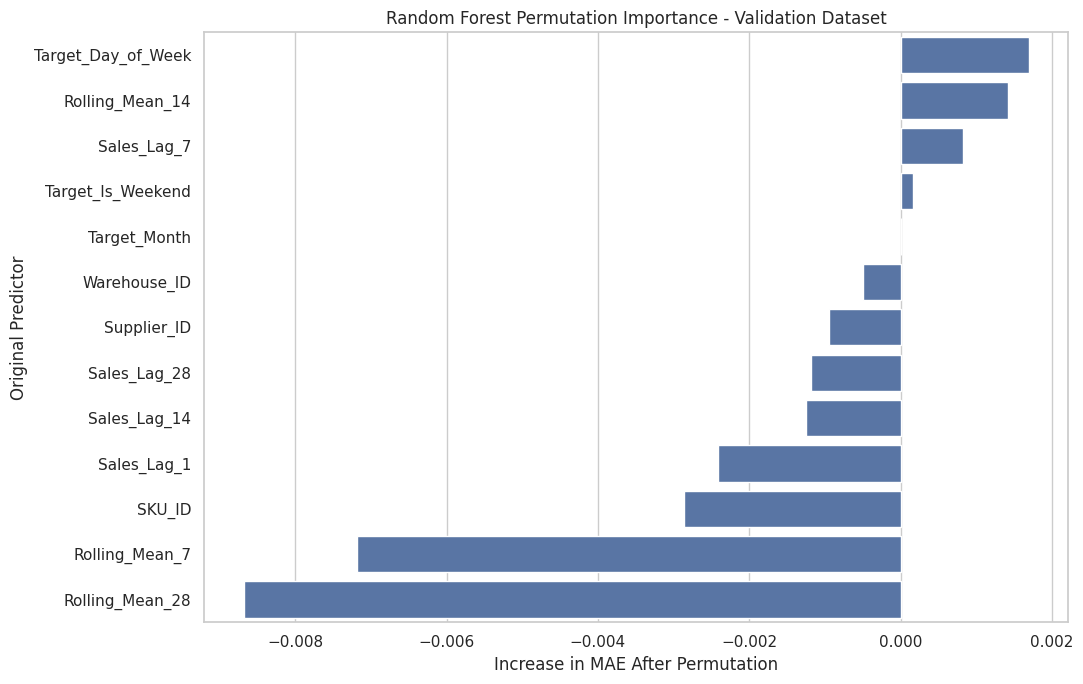

In [44]:

# STEP 10.8.1: Calculate permutation feature importance on validation data

# Import permutation importance from scikit-learn.
from sklearn.inspection import permutation_importance

# Calculate permutation importance using validation observations.
permutation_results = permutation_importance(
    random_forest_model,
    X_validation,
    y_validation,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create a DataFrame containing the original predictor names.
permutation_importance_df = pd.DataFrame(
    {
        "Feature": X_validation.columns,
        "Importance_Mean": permutation_results.importances_mean,
        "Importance_Std": permutation_results.importances_std
    }
)

# Sort predictors by their mean permutation importance.
permutation_importance_df = (
    permutation_importance_df
    .sort_values(
        by="Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the permutation importance results.
print("VALIDATION PERMUTATION FEATURE IMPORTANCE")
print("=" * 85)

display(
    permutation_importance_df.round(4)
)

# Visualise the mean permutation importance.
plt.figure(figsize=(11, 7))

sns.barplot(
    data=permutation_importance_df,
    x="Importance_Mean",
    y="Feature"
)

plt.title(
    "Random Forest Permutation Importance - Validation Dataset"
)

plt.xlabel(
    "Increase in MAE After Permutation"
)

plt.ylabel("Original Predictor")

plt.tight_layout()
plt.show()



### 10.8 Permutation Feature Importance

#### Objective

Permutation importance was calculated to evaluate how much the Random Forest model depended on individual predictors when generating predictions for unseen validation observations.

Unlike impurity-based feature importance, permutation importance evaluates the effect of randomly shuffling a predictor on model performance.

#### Method

Permutation importance was calculated using:

- The fitted Random Forest pipeline.
- The validation dataset.
- Negative mean absolute error as the scoring metric.
- Five permutation repetitions.
- A fixed random state of 42.

The importance values represent the increase in MAE after a predictor is shuffled.

Positive values indicate that shuffling a predictor worsened performance. Negative values indicate that shuffling slightly improved performance.

#### Results

The largest mean permutation importance values were:

| Feature | Mean Importance | Standard Deviation |
|---|---:|---:|
| Target_Day_of_Week | 0.0017 | 0.0016 |
| Rolling_Mean_14 | 0.0014 | 0.0019 |
| Sales_Lag_7 | 0.0008 | 0.0014 |
| Target_Is_Weekend | 0.0002 | 0.0002 |
| Target_Month | 0.0000 | 0.0000 |

Several predictors had negative mean permutation importance, including Rolling_Mean_7 (-0.0072) and Rolling_Mean_28 (-0.0087).

#### Comparison with impurity-based importance

The impurity-based analysis assigned 84.52% importance to Target_Month.

However, permutation importance showed approximately zero impact on validation MAE when Target_Month was shuffled.

This difference demonstrates that a feature's internal importance within a fitted tree model does not necessarily translate into measurable predictive value on unseen observations.

#### Limitations

Permutation importance can underestimate the contribution of correlated predictors because other predictors may contain overlapping information.

Only five permutations were performed. The results are therefore exploratory and should not be interpreted as definitive evidence that individual predictors have no predictive value.

#### Conclusion

The permutation analysis did not identify a predictor with a large and clearly stable individual contribution to validation accuracy.

The disagreement between impurity-based and permutation importance highlights the need to distinguish internal model structure from out-of-sample predictive usefulness.

The independent test evaluation remains unchanged: the seven-day rolling-mean benchmark outperformed Random Forest.


In [45]:

# STEP 10.9.1: Prepare correctly aligned test-period predictions

# Reconstruct the test rows using their verified target-date boundaries.
test_rows_correct = (
    df_model.loc[
        df_model["Target_Date"].between(
            "2024-11-10",
            "2024-12-30"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

# Reconstruct the test feature matrix and actual target values.
X_test_correct = (
    test_rows_correct[X_test.columns]
    .reset_index(drop=True)
)

y_test_correct = (
    test_rows_correct["Target_Next_Day_Units_Sold"]
    .reset_index(drop=True)
)

# Confirm that the reconstructed test data matches the original test data.
print("TEST DATA ALIGNMENT CHECK")
print("=" * 65)

print(
    "Numerical predictors match:",
    np.allclose(
        X_test_correct.select_dtypes(include=np.number),
        X_test.reset_index(drop=True).select_dtypes(include=np.number)
    )
)

print(
    "Categorical predictors match:",
    X_test_correct.select_dtypes(exclude=np.number).equals(
        X_test.reset_index(drop=True).select_dtypes(exclude=np.number)
    )
)

print(
    "Target values match:",
    np.allclose(
        y_test_correct,
        y_test.reset_index(drop=True)
    )
)

# Build a test-period prediction DataFrame.
final_test_predictions_df = pd.DataFrame(
    {
        "Target_Date": test_rows_correct["Target_Date"].to_numpy(),

        "Actual_Sales": y_test_correct.to_numpy(),

        "Rolling_Mean_Prediction": (
            X_test_correct["Rolling_Mean_7"].to_numpy()
        ),

        "Random_Forest_Prediction": (
            random_forest_model.predict(X_test_correct)
        ),

        "Linear_Regression_Prediction": (
            linear_model.predict(X_test_correct)
        )
    }
)

# Sort predictions chronologically.
final_test_predictions_df = (
    final_test_predictions_df
    .sort_values("Target_Date")
    .reset_index(drop=True)
)

# Calculate daily average actuals and predictions across all groups.
daily_test_predictions = (
    final_test_predictions_df
    .groupby("Target_Date")
    .agg(
        Actual_Sales=("Actual_Sales", "mean"),

        Rolling_Mean_Prediction=(
            "Rolling_Mean_Prediction", "mean"
        ),

        Random_Forest_Prediction=(
            "Random_Forest_Prediction", "mean"
        ),

        Linear_Regression_Prediction=(
            "Linear_Regression_Prediction", "mean"
        )
    )
    .reset_index()
)

# Display the first and last observations.
print("\nDAILY TEST PREDICTION SUMMARY")
print("=" * 65)

display(
    daily_test_predictions.head().round(4)
)

display(
    daily_test_predictions.tail().round(4)
)


TEST DATA ALIGNMENT CHECK
Numerical predictors match: True
Categorical predictors match: True
Target values match: True

DAILY TEST PREDICTION SUMMARY


,Target_Date,Actual_Sales,Rolling_Mean_Prediction,Random_Forest_Prediction,Linear_Regression_Prediction
0,2024-11-10,12.5960,11.8766,10.1867,7.0124
1,2024-11-11,12.5360,11.9983,10.5283,7.1217
2,2024-11-12,12.0840,12.1577,10.3596,7.1623
3,2024-11-13,12.2520,12.2697,10.2614,7.2036
4,2024-11-14,12.8680,12.3857,10.1979,7.2553


,Target_Date,Actual_Sales,Rolling_Mean_Prediction,Random_Forest_Prediction,Linear_Regression_Prediction
46,2024-12-26,19.1400,18.6903,12.8292,10.6373
47,2024-12-27,19.5800,18.8383,12.7066,10.7392
48,2024-12-28,19.7760,19.0531,12.5119,10.9005
49,2024-12-29,20.0000,19.1531,12.6346,11.0031
50,2024-12-30,20.0920,19.4154,13.0412,11.1861


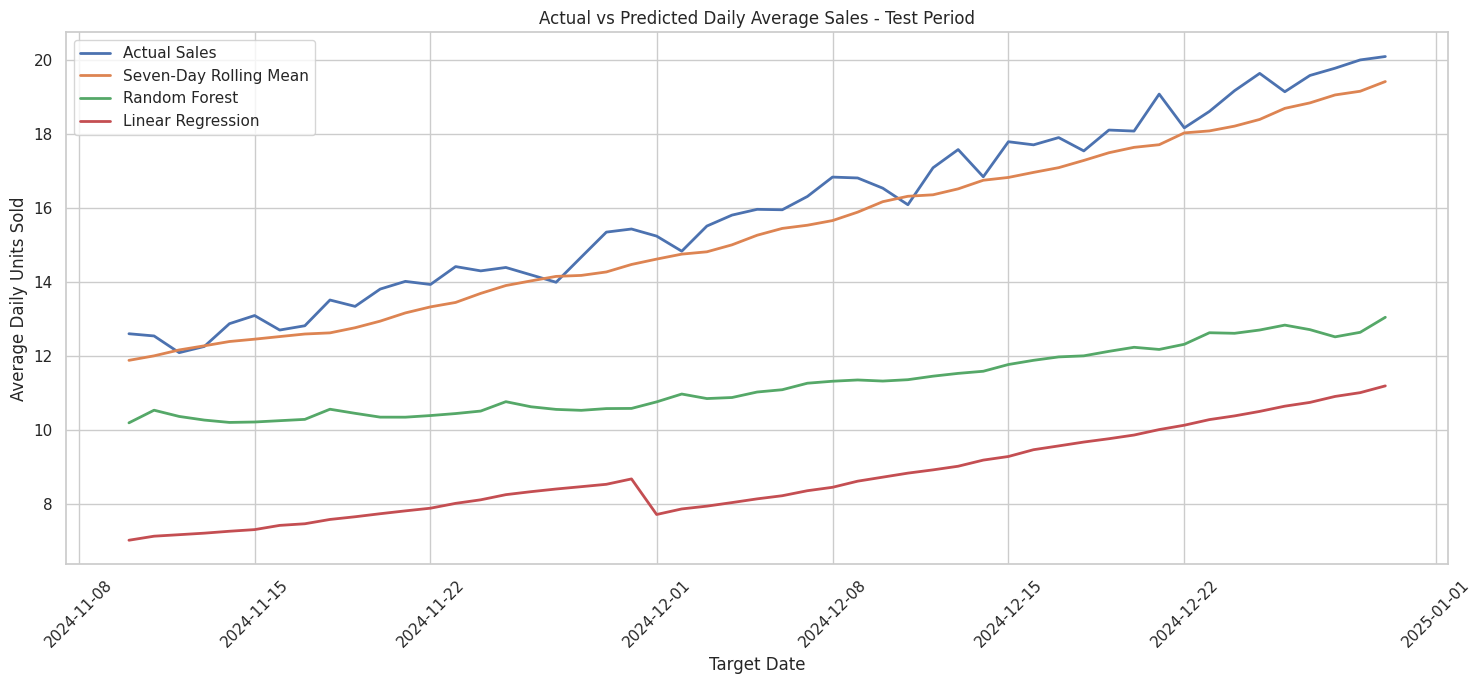

In [46]:

# STEP 10.9.2: Visualise actual and predicted daily demand

# Create a figure for the daily actual and predicted sales.
plt.figure(figsize=(15, 7))

# Plot actual daily average sales.
plt.plot(
    daily_test_predictions["Target_Date"],
    daily_test_predictions["Actual_Sales"],
    label="Actual Sales",
    linewidth=2
)

# Plot the seven-day rolling-mean benchmark.
plt.plot(
    daily_test_predictions["Target_Date"],
    daily_test_predictions["Rolling_Mean_Prediction"],
    label="Seven-Day Rolling Mean",
    linewidth=2
)

# Plot Random Forest predictions.
plt.plot(
    daily_test_predictions["Target_Date"],
    daily_test_predictions["Random_Forest_Prediction"],
    label="Random Forest",
    linewidth=2
)

# Plot Linear Regression predictions.
plt.plot(
    daily_test_predictions["Target_Date"],
    daily_test_predictions["Linear_Regression_Prediction"],
    label="Linear Regression",
    linewidth=2
)

# Add chart labels and formatting.
plt.title(
    "Actual vs Predicted Daily Average Sales - Test Period"
)

plt.xlabel("Target Date")
plt.ylabel("Average Daily Units Sold")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



### 10.9 Actual vs Predicted Demand: Test-Period Diagnostics

#### Objective

The final diagnostic compared actual daily average sales with predictions from the seven-day rolling-mean benchmark, Linear Regression and Random Forest.

#### Data validation

The test-period prediction dataset was reconstructed using the verified target-date boundaries.

All alignment checks passed:

- Numerical predictors matched the original test dataset.
- Categorical predictors matched the original test dataset.
- Target values matched the original test dataset.

The reconstructed dataset contained 12,750 observations covering 10 November to 30 December 2024.

#### Observed demand recovery

Actual average daily sales increased from 12.5960 units on 10 November to 20.0920 units on 30 December.

The corresponding predictions were:

| Date | Actual Sales | Rolling Mean | Random Forest | Linear Regression |
|---|---:|---:|---:|---:|
| 10 November | 12.5960 | 11.8766 | 10.1867 | 7.0124 |
| 30 December | 20.0920 | 19.4154 | 13.0412 | 11.1861 |

The rolling-mean benchmark followed the increase in observed demand more closely than either machine-learning model.

Random Forest substantially underpredicted demand, particularly towards the end of December.

Linear Regression also consistently underpredicted aggregate demand.

#### Interpretation

The prediction diagnostics reinforce the test-set evaluation.

The seven-day rolling mean adapted more effectively to the changing demand level because it incorporated recent observed sales.

The machine-learning models did not respond sufficiently to the demand recovery during the testing period.

These observations are aggregate daily averages across the SKU-warehouse groups. They should not be interpreted as evidence that every individual group experienced identical demand behaviour.

#### Conclusion

The visual and numerical diagnostics support the selection of the seven-day rolling-mean benchmark as the strongest of the three evaluated approaches on the independent testing dataset.

The machine-learning models did not demonstrate superior forecasting performance over the benchmark.



# 11. Final Conclusions and Recommendations

## 11.1 Project objective

The objective of this notebook was to develop and evaluate machine-learning approaches for predicting next-day units sold for individual SKU-warehouse combinations.

The analysis used chronological training, validation and testing partitions to preserve the temporal ordering of observations.

## 11.2 Modelling approach

Three forecasting approaches were evaluated:

1. Seven-Day Rolling Mean benchmark.
2. Linear Regression.
3. Random Forest Regression.

The predictive features included historical sales lags, rolling sales averages, calendar variables and categorical SKU, warehouse and supplier identifiers.

Categorical variables were one-hot encoded.

The machine-learning models were trained using the training dataset and evaluated using the validation dataset before final evaluation on the independent testing dataset.

## 11.3 Final model performance

| Model | Test MAE | Test RMSE | Test R² | Test MFE |
|---|---:|---:|---:|---:|
| Seven-Day Rolling Mean | 4.5063 | 5.6986 | 0.0359 | 0.6058 |
| Linear Regression | 7.6764 | 9.1014 | -1.4592 | 7.2427 |
| Random Forest | 5.8751 | 7.2974 | -0.5810 | 4.7115 |

The seven-day rolling-mean benchmark achieved the best test performance.

Random Forest recorded a test MAE approximately 30.38% higher than the benchmark, while Linear Regression recorded substantially higher prediction errors.

Both machine-learning models underforecasted average test demand.

## 11.4 Generalisation assessment

Random Forest outperformed the rolling-mean benchmark during validation but failed to maintain that advantage on the independent test dataset.

The training, validation and testing partitions also exhibited substantially different average demand levels.

Average actual sales were:

- Training: 22.7288 units.
- Validation: 10.4549 units.
- Testing: 15.9595 units.

This indicates that the forecasting task involved changing demand levels across the chronological partitions.

The test-period diagnostics showed that the rolling-mean benchmark adapted more closely to the partial demand recovery during November and December.

## 11.5 Feature importance findings

Impurity-based feature importance assigned 84.52% importance to Target_Month.

However, permutation importance on validation data showed approximately zero importance for Target_Month.

This difference illustrates that internal tree-splitting importance does not necessarily translate into measurable predictive value on unseen observations.

The permutation analysis did not identify a predictor with a large and clearly stable individual contribution to validation accuracy.

## 11.6 Key limitations

The analysis has several limitations:

1. The dataset covers only one year, limiting the ability to establish recurring annual seasonal patterns.
2. The cause of the substantial demand-level changes across partitions is unknown.
3. The supplied Stockout_Flag is constant and was excluded from predictive modelling.
4. The timing and operational meaning of several potential predictors were uncertain, so they were excluded.
5. The forecast is a one-step-ahead daily prediction using observed sales available through the forecast-origin date. It is not a fixed multi-week-ahead forecast.
6. The same SKU, warehouse and supplier categories occur across the chronological partitions. The evaluation therefore does not establish performance on previously unseen categories.
7. Model performance may vary across individual SKU-warehouse groups, even where aggregate metrics appear stable.

## 11.7 Operational recommendations

Based on the evaluated results:

- Prefer the seven-day rolling-mean benchmark among the three approaches tested.
- Monitor forecast errors over time, particularly when demand levels change.
- Investigate the operational causes of demand variation before introducing additional predictors.
- Improve data documentation, especially for stockout indicators and replenishment variables.
- Collect additional historical periods before drawing conclusions about recurring seasonal patterns.
- Evaluate forecasting performance at SKU and warehouse level before operational deployment.

## 11.8 Final conclusion

This project demonstrates that more complex machine-learning models do not automatically outperform simple forecasting benchmarks.

Although Random Forest achieved better validation performance, the independent testing results favoured the seven-day rolling mean.

The final evaluation therefore supports the rolling-mean benchmark as the strongest of the three methods investigated.

The most important outcome is not that a machine-learning model was successfully trained, but that the models were evaluated critically, their limitations were identified, and the final recommendation was based on independent test performance.
